# 01 · EDA de los recursos disponibles para el alumno

**Bloque del objetivo.** La pregunta del TFM es cómo ha cambiado entre 2012 y 2022 la relación del esfuerzo del alumno y de los recursos de que dispone con su nota de matemáticas, según el perfil de su centro. Para eso hace falta medir los recursos del alumno por separado de su origen social. Este notebook construye esa medida a partir de las preguntas de posesiones del hogar del cuestionario del alumno, en las ediciones 2012, 2015, 2018 y 2022, con los 33 países (los países del análisis se fijan en `01_EDA_variables_modelo`). Se miran también lectura y ciencias para comprobar que los resultados no dependen de la asignatura.

Preguntas que responde:

* ¿Qué recoge `HOMEPOS` y por qué no basta con usarlo tal cual? (sección 1)
* ¿Qué preguntas del hogar se pueden comparar entre 2012 y 2022, y cómo se armonizan? (sección 2)
* ¿Cuántos alumnos tienen cada recurso, y en qué países faltan? (sección 3)
* ¿Cómo se resumen en subíndices, y son coherentes con los índices oficiales de la OCDE? (secciones 4 y 5)
* ¿Qué alumnos se quedan sin subíndice, y en qué países? (sección 6)
* ¿Cómo evolucionan dentro de cada país, y dónde está su variación: entre países, entre ediciones, entre centros o entre alumnos? (secciones 7 y 8)
* ¿Cómo se relacionan con la nota, una vez descontado el origen social de la familia? ¿Los libros en casa son un recurso o capital cultural? (secciones 9 y 10)
* ¿Qué recursos del centro percibe el alumno y se pueden comparar entre ediciones? (sección 11)
* ¿Cambiaría algo construir el subíndice de recursos de estudio con IRT en lugar de sumar ítems? (sección 12)

Decisiones de partida: el modelo usará subíndices (suma de ítems) y no ítems sueltos, que aquí sirven para describir; la comprobación con modelos de respuesta al ítem (IRT) se hace comparando los subíndices con los índices oficiales de la OCDE, que están calculados con IRT. La armonización y los subíndices están en `src/recursos_alumno.py`. Las correlaciones, regresiones y repartos de varianza de la nota se calculan con cada valor plausible por separado y se promedian (`estimar_con_pv`); las medias de la nota usan la media de los valores plausibles de cada alumno.

Los recursos del centro según el director están en la sección 6 de `01_EDA_equidad`. En el modelo, los recursos se comparan dentro de perfiles de centro de características fijas, definidos a mano para que sean comparables entre ediciones (`00_Pipeline_generacion_estratos`).

## 0. Configuración

In [1]:
import os
import re
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadstat
import seaborn as sns
from IPython.display import display

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.pisa_estadisticas import agregar_media_ponderada, centrar_en_grupos, estimar_con_pv, regresion_dentro_de_grupos, reparto_varianza
from src.pisa_pipeline import columnas_pv, rutas_datos_anuales
from src.recursos_alumno import (CLAVES_ALUMNO, EDICIONES_RECURSOS, HAY_ALGUNO, ITEMS_HOGAR, PESOS_ALUMNO, RESPUESTAS_MINIMAS, SI_NO,
                                 SUBINDICES, alfa_cronbach, calibrar_rasch, construir_subindices, leer_items_hogar, puntuacion_eap)

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200)

RUTA_RAW_BASE = '../../data/raw'
RUTA_INTERMEDIOS = '../../data/intermediate'
RUTA_REPORTS = '../../reports'
INDICES_OFICIALES = ['HOMEPOS', 'HOMEPOS_TREND', 'WEALTH', 'CULTPOSS', 'HEDRES', 'ICTRES']
# Nota, origen social (versiones comparables entre ediciones) y recursos del centro vistos por el alumno
ASIGNATURAS = {'matemáticas': 'MATH', 'lectura': 'READ', 'ciencias': 'SCIE'}   # con todos sus valores plausibles (5 en 2012)
COLUMNAS_CONTEXTO = [columna for dominio in ASIGNATURAS.values() for columna in columnas_pv(dominio)] + ['ESCS_TREND', 'HISEI_TREND', 'PAREDINT_TREND', 'TEACHSUP', 'ICTSCH']

# Ítems del hogar armonizados y subíndices, con los índices oficiales y la nota, una fila por alumno
alumnos = construir_subindices(pd.concat([leer_items_hogar(RUTA_RAW_BASE, edicion, INDICES_OFICIALES + COLUMNAS_CONTEXTO) for edicion in EDICIONES_RECURSOS],
                                         ignore_index=True))
print(f"{len(alumnos)} alumnos de {alumnos['CNT'].nunique()} países")
alumnos.groupby('year').size().rename('alumnos').to_frame().T

1066807 alumnos de 33 países


year,2012,2015,2018,2022
alumnos,290158,238452,269587,268610


## 1. Qué recoge `HOMEPOS`

`HOMEPOS` es el índice de posesiones del hogar de PISA. Resume, con un modelo de respuesta al ítem, las preguntas sobre lo que hay en casa del alumno: espacio y material de estudio (habitación propia, ordenador, internet), libros, objetos culturales, bienestar material (coches, baños) y dispositivos. Es uno de los tres componentes del índice socioeconómico (`ESCS`), junto con la ocupación (`HISEI`) y la educación de los padres (`PAREDINT`), y la OCDE lo usa como sustituto de los ingresos del hogar, que PISA no pregunta (*PISA 2022 Technical Report*, capítulo 19).

Las preguntas cambian entre ediciones; en 2022 el bloque se rehízo. Para comparar las ediciones, la OCDE volvió a calcular el índice de 2012-2018 con los parámetros de 2022 (`HOMEPOS_TREND`, que las tablas maestras incorporan de `escs_trend.csv`). Hasta 2018 existen además los subíndices de riqueza (`WEALTH`), posesiones culturales (`CULTPOSS`), recursos educativos del hogar (`HEDRES`) y TIC (`ICTRES`, desde 2015).

La tabla cuenta, por edición, las preguntas de posesiones del hogar y el % de alumnos con cada índice oficial.

In [2]:
diccionario = pd.read_csv(os.path.join(RUTA_INTERMEDIOS, 'diccionario_columnas.csv'), encoding='utf-8-sig')
PREGUNTAS_POSESIONES = {2012: r'^ST2[678]Q', 2015: r'^ST01[123]Q', 2018: r'^ST01[123]Q', 2022: r'^ST25[0-6]'}
columnas_estudiantes = diccionario[diccionario['TABLA'] == 'estudiantes']
numero_preguntas = {edicion: int(columnas_estudiantes.loc[columnas_estudiantes['EDICION'] == edicion, 'COLUMNA'].str.match(patron).sum())
                    for edicion, patron in PREGUNTAS_POSESIONES.items()}

cobertura_indices = alumnos.groupby('year')[INDICES_OFICIALES].apply(lambda grupo: grupo.notna().mean().mul(100).round(1))
cobertura_indices.insert(0, 'preguntas de posesiones', pd.Series(numero_preguntas))
cobertura_indices

,preguntas de posesiones,HOMEPOS,HOMEPOS_TREND,WEALTH,CULTPOSS,HEDRES,ICTRES
year,,,,,,,
2012,23,98.7,98.7,98.7,97.4,98.5,0.0
2015,22,98.3,98.3,97.9,96.6,97.7,97.8
2018,22,97.3,97.3,97.0,96.1,97.0,96.9
2022,31,97.2,97.2,0.0,0.0,0.0,41.3


**Qué se ve.**

* **Las preguntas de posesiones cambian entre ediciones**: 23 en 2012, 22 en 2015 y 2018 y 31 en 2022.
* **`HOMEPOS` y su versión comparable entre ediciones, `HOMEPOS_TREND`, existen en las cuatro ediciones**, para entre el 97,2 % y el 98,7 % de los alumnos.
* **Los subíndices oficiales desaparecen en 2022**: riqueza, posesiones culturales y recursos educativos del hogar solo existen hasta 2018, y el índice de TIC pasa del 97-98 % de los alumnos en 2015 y 2018 al 41,3 % en 2022.

Para separar los recursos de estudio de la riqueza en todas las ediciones hacen falta subíndices propios.

## 2. Armonización de las preguntas del hogar

Cada ítem tiene una columna distinta según la edición (`ITEMS_HOGAR` en `src/recursos_alumno.py`) y se recodifica a una escala común:

* **Sí/no** (habitación propia, ordenador para los estudios, internet, escritorio, sitio tranquilo para estudiar, software educativo): 1 = lo tiene, 0 = no.
* **Cuántos** (coches, baños): de 0 (ninguno) a 3 (tres o más); las categorías son las mismas en todas las ediciones.
* **Tramos** (libros en casa): de 1 (0-10 libros) a 6 (más de 500). En 2022 la escala empieza en «ningún libro», que se junta con «1-10» para formar la categoría «0-10» de las ediciones anteriores.
* **Hay alguno** (libros de ayuda para los estudios, libros técnicos de consulta, diccionario): hasta 2018 se pregunta si los hay (sí/no); en 2022, cuántos hay de cada tipo, y se convierte en «tiene al menos uno». En 2022 la pregunta tiene cinco códigos y el fichero no trae sus etiquetas: según el codebook de PISA 2022, los códigos 1 a 4 van de menos a más (1 = ninguno, 2 = de 1 a 5, 3 = de 6 a 10, 4 = más de 10) y el 5 es «no lo sé», que se trata como vacío. La celda siguiente lo comprueba también con los datos.

Quedan fuera los ítems que no se pueden igualar: los televisores y los ordenadores (en 2022 se cuentan con otras categorías) y los ítems propios de cada país. El escritorio y el sitio tranquilo solo existen hasta 2018, y el software educativo cambia de pregunta en 2022 («o apps»).

Las etiquetas de las categorías están en el fichero original de 2012, pero no en el de 2022 (el fichero SAS de la OCDE no las incluye). Por eso, para ver qué preguntas cambian de escala se compara el reparto de respuestas de 2018 y 2022: una pregunta con las mismas categorías tiene el mismo número de códigos y un reparto parecido. Para los tipos de libros de 2022 se mira, además, el `ESCS` medio y el número de libros en casa de los alumnos en cada código: si un código fuera la categoría más alta, sus alumnos tendrían los valores más altos.

In [3]:
correspondencia = pd.DataFrame({item: {'respuesta': tipo, **{edicion: columnas.get(edicion, '-') for edicion in EDICIONES_RECURSOS}}
                                for item, (tipo, columnas) in ITEMS_HOGAR.items()}).T
display(correspondencia)

# Etiquetas de las categorías en 2012 y reparto de las respuestas en 2018 y 2022 (% de alumnos con respuesta en cada código)
_, metadatos_2012 = pyreadstat.read_sav(os.path.join(RUTA_RAW_BASE, '2012', 'INT_STU12_DEC03.sav'), metadataonly=True)
COMPARADAS = {'coches': ('ST27Q04', 'ST012Q02TA', 'ST251Q01JA'), 'libros en casa': ('ST28Q01', 'ST013Q01TA', 'ST255Q01JA'),
              'televisores': ('ST27Q02', 'ST012Q01TA', 'ST254Q01JA'), 'ordenadores (2022: de sobremesa)': ('ST27Q03', 'ST012Q06NA', 'ST254Q02JA')}
respuestas_2018 = pd.read_parquet(rutas_datos_anuales(RUTA_RAW_BASE, 2018)[0], columns=[columnas[1] for columnas in COMPARADAS.values()])
respuestas_2022 = pd.read_parquet(rutas_datos_anuales(RUTA_RAW_BASE, 2022)[0], columns=[columnas[2] for columnas in COMPARADAS.values()])
for concepto, (columna_2012, columna_2018, columna_2022) in COMPARADAS.items():
    etiquetas_2012 = [etiqueta for codigo, etiqueta in metadatos_2012.variable_value_labels[columna_2012].items() if codigo < 7]
    print(f'{concepto}. Categorías en 2012 ({columna_2012}): {etiquetas_2012}')
    for edicion, respuestas, columna in ((2018, respuestas_2018, columna_2018), (2022, respuestas_2022, columna_2022)):
        reparto = respuestas[columna].value_counts(normalize=True).sort_index().mul(100).round(1)
        print(f'  {edicion} ({columna}): ' + ', '.join(f'código {int(codigo)}: {porcentaje} %' for codigo, porcentaje in reparto.items()))

# Tipos de libros en 2022: % de alumnos, ESCS medio y tramo medio de libros en casa (ST255, 1 a 7) en cada código
TIPOS_LIBROS_2022 = {item: columnas[2022] for item, (tipo, columnas) in ITEMS_HOGAR.items() if tipo == HAY_ALGUNO}
libros_2022 = pd.read_parquet(rutas_datos_anuales(RUTA_RAW_BASE, 2022)[0], columns=['ESCS', 'ST255Q01JA'] + list(TIPOS_LIBROS_2022.values()))
for item, columna in TIPOS_LIBROS_2022.items():
    resumen = libros_2022.groupby(columna).agg(escs_medio=('ESCS', 'mean'), tramo_libros_medio=('ST255Q01JA', 'mean'))
    resumen.insert(0, '% de alumnos', libros_2022[columna].value_counts(normalize=True).mul(100))
    print(f'\n{item} ({columna}):')
    display(resumen.round(2))

,respuesta,2012,2015,2018,2022
habitacion_propia,sí/no,ST26Q02,ST011Q02TA,ST011Q02TA,ST250Q01JA
ordenador_estudios,sí/no,ST26Q04,ST011Q04TA,ST011Q04TA,ST250Q02JA
internet,sí/no,ST26Q06,ST011Q06TA,ST011Q06TA,ST250Q05JA
escritorio,sí/no,ST26Q01,ST011Q01TA,ST011Q01TA,-
sitio_tranquilo,sí/no,ST26Q03,ST011Q03TA,ST011Q03TA,-
software_educativo,sí/no,ST26Q05,ST011Q05TA,ST011Q05TA,ST250Q03JA
libros_ayuda_estudios,hay alguno,ST26Q10,ST011Q10TA,ST011Q10TA,ST256Q10JA
libros_tecnicos,hay alguno,ST26Q11,ST011Q11TA,ST011Q11TA,ST256Q08JA
diccionario,hay alguno,ST26Q12,ST011Q12TA,ST011Q12TA,ST256Q09JA
coches,cuántos,ST27Q04,ST012Q02TA,ST012Q02TA,ST251Q01JA


coches. Categorías en 2012 (ST27Q04): ['None', 'One', 'Two', 'Three or more']
  2018 (ST012Q02TA): código 1: 6.7 %, código 2: 30.5 %, código 3: 42.3 %, código 4: 20.4 %
  2022 (ST251Q01JA): código 1: 9.0 %, código 2: 31.0 %, código 3: 40.8 %, código 4: 19.3 %
libros en casa. Categorías en 2012 (ST28Q01): ['0-10 books', '11-25 books', '26-100 books', '101-200 books', '201-500 books', 'More than 500 books']
  2018 (ST013Q01TA): código 1: 14.3 %, código 2: 16.2 %, código 3: 29.8 %, código 4: 18.1 %, código 5: 14.1 %, código 6: 7.4 %
  2022 (ST255Q01JA): código 1: 4.3 %, código 2: 13.6 %, código 3: 16.4 %, código 4: 30.0 %, código 5: 16.9 %, código 6: 12.8 %, código 7: 6.0 %
televisores. Categorías en 2012 (ST27Q02): ['None', 'One', 'Two', 'Three or more']
  2018 (ST012Q01TA): código 1: 1.4 %, código 2: 19.5 %, código 3: 31.6 %, código 4: 47.5 %
  2022 (ST254Q01JA): código 1: 1.6 %, código 2: 52.2 %, código 3: 39.9 %, código 4: 5.8 %, código 5: 0.4 %
ordenadores (2022: de sobremesa). Categ

,% de alumnos,escs_medio,tramo_libros_medio
ST256Q10JA,,,
1.0,14.08,-0.37,3.47
2.0,36.90,-0.02,3.86
3.0,18.68,0.25,4.40
4.0,18.53,0.46,5.02
5.0,11.81,0.29,4.51



libros_tecnicos (ST256Q08JA):


,% de alumnos,escs_medio,tramo_libros_medio
ST256Q08JA,,,
1.0,26.76,-0.43,3.41
2.0,32.68,0.13,4.11
3.0,11.27,0.45,4.77
4.0,9.46,0.69,5.36
5.0,19.82,0.34,4.57



diccionario (ST256Q09JA):


,% de alumnos,escs_medio,tramo_libros_medio
ST256Q09JA,,,
1.0,11.12,-0.36,3.25
2.0,62.43,0.05,4.07
3.0,12.15,0.45,4.98
4.0,5.13,0.69,5.61
5.0,9.17,0.31,4.39


**Qué se ve.**

* **Coches**: cuatro categorías («None, One, Two, Three or more» en 2012) y un reparto casi igual en 2018 y 2022 (por ejemplo, el código 3 recoge al 42,3 % y al 40,8 % de los alumnos). Se comparan sin más; los baños tienen las mismas categorías.
* **Libros en casa**: 2022 tiene un código más. El reparto encaja desplazado una posición (el código 3 de 2018 recoge al 29,8 % y el código 4 de 2022, al 30,0 %), lo que confirma que 2022 añade una categoría al principio («ningún libro») que se junta con la siguiente: «0-10 libros» pasa del 14,3 % de 2018 al 17,9 % de 2022 (4,3 % + 13,6 %).
* **Televisores y ordenadores**: el reparto no encaja. El código 4 («tres o más» hasta 2018) recoge al 47,5 % de los alumnos en televisores en 2018 y al 5,8 % en 2022; en ordenadores, al 42,5 % frente al 1,5 %. La escala cambió y no se pueden comparar.
* **Tipos de libros en 2022**: en los códigos 1 a 4, el `ESCS` medio y el número de libros en casa suben de forma ordenada (por ejemplo, en libros técnicos el `ESCS` pasa de −0,43 a 0,69, y el tramo de libros, de 3,41 a 5,36). El código 5, que recoge entre el 9,2 % y el 19,8 % de los alumnos, queda a medio camino (`ESCS` de 0,29 a 0,34 y tramo de 4,39 a 4,57): no es la categoría más alta, sino «no lo sé», como dice el codebook, y se trata como vacío.

## 3. Cuántos alumnos tienen cada recurso

Un recurso que casi todos los alumnos tienen aporta poca información: quienes no lo tienen son una minoría concreta. Para cada ítem de sí/no o de «hay alguno», el % de alumnos que lo tiene en la OCDE (cada país pesa igual, con `SENWT`) y, por país (con `W_FSTUWT`), el país donde menos alumnos lo tienen y cuántos países quedan por debajo del 80 %. Un salto entre dos ediciones en la media de la OCDE indica un cambio de pregunta más que de realidad.

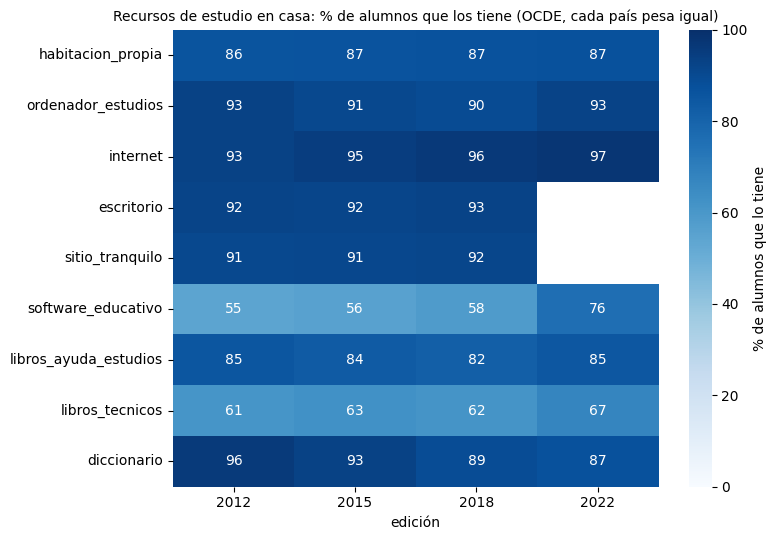

país con menos                % en ese país                   países por debajo del 80 %                  
edición                         2012 2015 2018 2022          2012  2015  2018  2022                       2012  2015  2018  2022
ítem                                                                                                                            
diccionario                      FIN  SWE  SWE  SWE          90.4  82.2  71.4  69.0                        0.0   0.0   3.0   7.0
escritorio                       CHL  CHL  CHL  NaN          71.3  75.2  75.3   NaN                        3.0   3.0   2.0   NaN
habitacion_propia                MEX  MEX  MEX  MEX          48.4  51.5  53.6  56.8                        8.0   7.0   6.0   4.0
internet                         MEX  MEX  MEX  MEX          47.4  54.2  67.9  86.2                        3.0   2.0   2.0   0.0
libros_ayuda_estudios            MEX  MEX  MEX  CHL          69.4  65.6  62.2  71.6                        7.0   9.0  12.0  10.0
libros_tecnicos                  MEX  MEX  MEX  MEX          32.5  29.9  29.5  40.8                       29.0  28.0  29.0  28.0
ordenador_estudios               MEX  MEX  MEX  MEX          57.3  56.5  56.8  66.3                        3.0   3.0   3.0   2.0
sitio_tranquilo                  MEX  MEX  MEX  NaN          71.8  73.0  74.4   NaN                        1.0   1.0   1.0   NaN
software_educativo               JPN  JPN  JPN  MEX          15.2  13.4  16.4  46.5                       32.0  31.0  29.0  18.0

Media de la OCDE de los ítems de cuántos (0 a 3) y de libros en casa (1 a 6):


,coches,baños,libros_en_casa
year,,,
2012,1.60,1.52,3.22
2015,1.67,1.57,3.24
2018,1.73,1.60,3.21
2022,1.68,1.54,3.06


In [4]:
ITEMS_BINARIOS = [item for item, (tipo, _) in ITEMS_HOGAR.items() if tipo in (SI_NO, HAY_ALGUNO)]
porcentaje_ocde = agregar_media_ponderada(alumnos, ITEMS_BINARIOS, claves=['year'], peso_col='SENWT').set_index('year')[ITEMS_BINARIOS].T.mul(100)
porcentaje_pais = agregar_media_ponderada(alumnos, ITEMS_BINARIOS, claves=['CNT', 'year'], peso_col='W_FSTUWT')

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(porcentaje_ocde, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, cbar_kws={'label': '% de alumnos que lo tiene'}, ax=ax)
ax.set_xlabel('edición')
ax.set_ylabel('')
ax.set_title('Recursos de estudio en casa: % de alumnos que los tiene (OCDE, cada país pesa igual)', fontsize=10)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_alumno_saturacion.png', dpi=300, bbox_inches='tight')
plt.show()

filas = []
for item in ITEMS_BINARIOS:
    for edicion, grupo in porcentaje_pais.dropna(subset=[item]).groupby('year'):
        minimo = grupo.loc[grupo[item].idxmin()]
        filas.append({'ítem': item, 'edición': edicion, 'país con menos': minimo['CNT'], '% en ese país': round(100 * minimo[item], 1),
                      'países por debajo del 80 %': int((grupo[item] < 0.8).sum())})
display(pd.DataFrame(filas).set_index(['ítem', 'edición']).unstack('edición'))

print('Media de la OCDE de los ítems de cuántos (0 a 3) y de libros en casa (1 a 6):')
agregar_media_ponderada(alumnos, ['coches', 'baños', 'libros_en_casa'], claves=['year'], peso_col='SENWT').set_index('year').round(2)

**Qué se ve.**

* **Casi todos los alumnos tienen la mayoría de los recursos de estudio**: en la OCDE, internet del 93 % al 97 % según la edición, el ordenador para los estudios del 90 % al 93 %, el escritorio del 92 % al 93 %, el sitio tranquilo del 91 % al 92 % y el diccionario del 87 % al 96 %. La habitación propia (del 86 % al 87 %) y los libros de ayuda para los estudios (del 82 % al 85 %), algo menos.
* **Los libros técnicos son el recurso que más distingue**: los tiene entre el 61 % y el 67 % de los alumnos, y entre 28 y 29 países quedan por debajo del 80 % en cada edición.
* **Donde faltan es sobre todo en México**: es el país con menos alumnos con habitación propia (del 48,4 % en 2012 al 56,8 % en 2022), internet (del 47,4 % al 86,2 %), ordenador (del 56,5 % al 66,3 %) y libros técnicos (del 29,5 % al 40,8 %). El diccionario es la excepción: falta sobre todo en países nórdicos (Suecia, con el 69,0 % en 2022).
* **El software educativo no es comparable**: salta del 58 % en 2018 al 76 % en 2022, cuando la pregunta añade «o apps», y en Japón lo tiene solo entre el 13,4 % y el 16,4 % de los alumnos hasta 2018 (entre 29 y 32 países por debajo del 80 %). Por eso no entra en los subíndices.
* **Los coches y los baños apenas cambian**: entre 1,60 y 1,73 coches y entre 1,52 y 1,60 baños de media (en la escala de 0 a 3). Los libros bajan de 3,21-3,24 hasta 2018 a 3,06 en 2022; como las categorías encajan (sección 2), la bajada parece real.

## 4. Subíndices

Cada subíndice es la suma de sus ítems (`SUBINDICES` en `src/recursos_alumno.py`). Si el alumno no respondió todos, la suma se estima como la media de los que respondió por el número de ítems, siempre que haya respondido el mínimo de `RESPUESTAS_MINIMAS` (4 de 6 en recursos de estudio; en los demás, todos):

* **Recursos de estudio** (0 a 6): habitación propia, ordenador para los estudios, internet, libros de ayuda para los estudios, libros técnicos de consulta y diccionario. Son los ítems del índice oficial de recursos educativos del hogar (`HEDRES`) que existen en las cuatro ediciones. Es la variable de interés (recurso del alumno).
* **Riqueza del hogar** (0 a 6): coches y baños. Es origen social, un control.
* **Libros en casa** (1 a 6): un solo ítem con seis categorías. Se trata como capital cultural de la familia, es decir, origen social (sección 10).

El software educativo no entra (cambia de pregunta en 2022), ni el escritorio y el sitio tranquilo (solo existen hasta 2018). Los libros de ayuda, técnicos y diccionario son libros útiles para estudiar; «libros en casa» es el número total de libros, que suele leerse como capital cultural de la familia.

Alumnos con el subíndice de recursos de estudio (%): {2012: 97.8, 2015: 97.2, 2018: 96.5, 2022: 84.6}


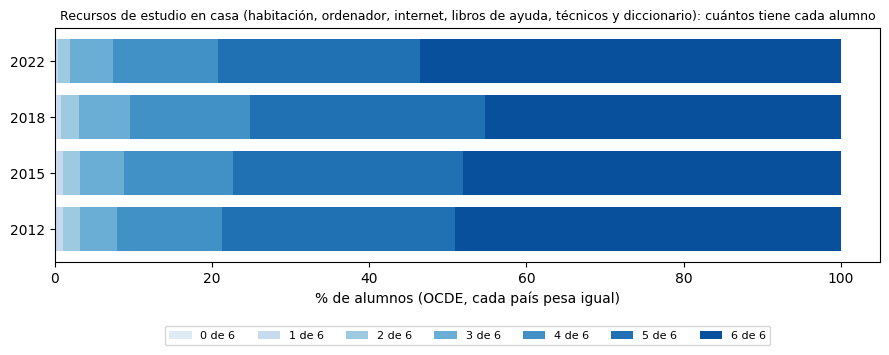

recursos_estudio,0.0,1.0,2.0,3.0,4.0,5.0,6.0
year,,,,,,,
2012,0.2,0.9,2.2,4.7,13.3,29.7,49.1
2015,0.2,0.8,2.2,5.5,13.9,29.3,48.1
2018,0.2,0.6,2.3,6.5,15.3,29.9,45.3
2022,0.1,0.3,1.6,5.4,13.4,25.7,53.6


Media de cada subíndice por edición (OCDE, cada país pesa igual):


,recursos_estudio,riqueza_hogar,libros
year,,,
2012,5.15,3.13,3.22
2015,5.12,3.24,3.24
2018,5.07,3.33,3.21
2022,5.23,3.22,3.06


In [5]:
# Recursos de estudio redondeado a entero (los alumnos que no respondieron todos los ítems tienen valores intermedios)
print('Alumnos con el subíndice de recursos de estudio (%):', alumnos.groupby('year')['recursos_estudio'].apply(lambda serie: round(100 * serie.notna().mean(), 1)).to_dict())
reparto_estudio = (alumnos.dropna(subset=['recursos_estudio']).groupby(['year', alumnos['recursos_estudio'].round()])['SENWT'].sum()
                   .groupby(level='year').transform(lambda serie: 100 * serie / serie.sum()).unstack('recursos_estudio'))
fig, ax = plt.subplots(figsize=(9, 3.8))
izquierda = np.zeros(len(reparto_estudio))
for valor, color in zip(reparto_estudio.columns, sns.color_palette('Blues', n_colors=len(reparto_estudio.columns))):
    ax.barh(reparto_estudio.index.astype(str), reparto_estudio[valor], left=izquierda, color=color, label=f'{int(valor)} de 6')
    izquierda += reparto_estudio[valor].to_numpy()
ax.set_xlabel('% de alumnos (OCDE, cada país pesa igual)')
ax.set_title('Recursos de estudio en casa (habitación, ordenador, internet, libros de ayuda, técnicos y diccionario): cuántos tiene cada alumno', fontsize=9)
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.25), ncols=7)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_alumno_subindice_estudio.png', dpi=300, bbox_inches='tight')
plt.show()
display(reparto_estudio.round(1))

print('Media de cada subíndice por edición (OCDE, cada país pesa igual):')
agregar_media_ponderada(alumnos, list(SUBINDICES), claves=['year'], peso_col='SENWT').set_index('year').round(2)

**Qué se ve.**

* **Cobertura**: el subíndice de recursos de estudio existe para el 96,5-97,8 % de los alumnos hasta 2018 y el 84,6 % en 2022, donde las preguntas de tipos de libros tienen más huecos (y el «no lo sé» cuenta como vacío).
* **La mayoría tiene casi todos los recursos**: entre el 45,3 % y el 53,6 % de los alumnos tiene los seis, y entre el 75,2 % y el 79,3 %, cinco o seis; con dos o menos solo queda entre el 2,0 % y el 3,3 %. La media va de 5,07 a 5,23 sobre 6.
* **Con seis ítems el subíndice tiene más recorrido** que con los tres de partida, gracias sobre todo a los libros técnicos y a los libros de ayuda. La riqueza del hogar (de 3,13 a 3,33 sobre 6) y los libros en casa (de 3,06 a 3,24 sobre 6) apenas cambian entre ediciones.

## 5. Validación de los subíndices

Dos comprobaciones:

* **Coherencia interna** (alfa de Cronbach, ponderado con `SENWT`): si los ítems de un subíndice miden algo común. Con pocos ítems, y casi todos con respuesta «sí», el alfa tiende a ser bajo aunque el subíndice sea útil.
* **Parecido con los índices oficiales**, calculados por la OCDE con IRT: la correlación de cada subíndice con `HOMEPOS_TREND`, `HOMEPOS`, `HEDRES` (recursos educativos), `WEALTH` (riqueza), `CULTPOSS` (posesiones culturales) e `ICTRES` (TIC). Si un subíndice se parece al índice oficial de su concepto, el resultado no depende de haber sumado ítems en lugar de usar IRT.

Alfa de Cronbach por edición:


,2012,2015,2018,2022
recursos_estudio,0.525,0.514,0.478,0.453
riqueza_hogar,0.546,0.531,0.524,0.490


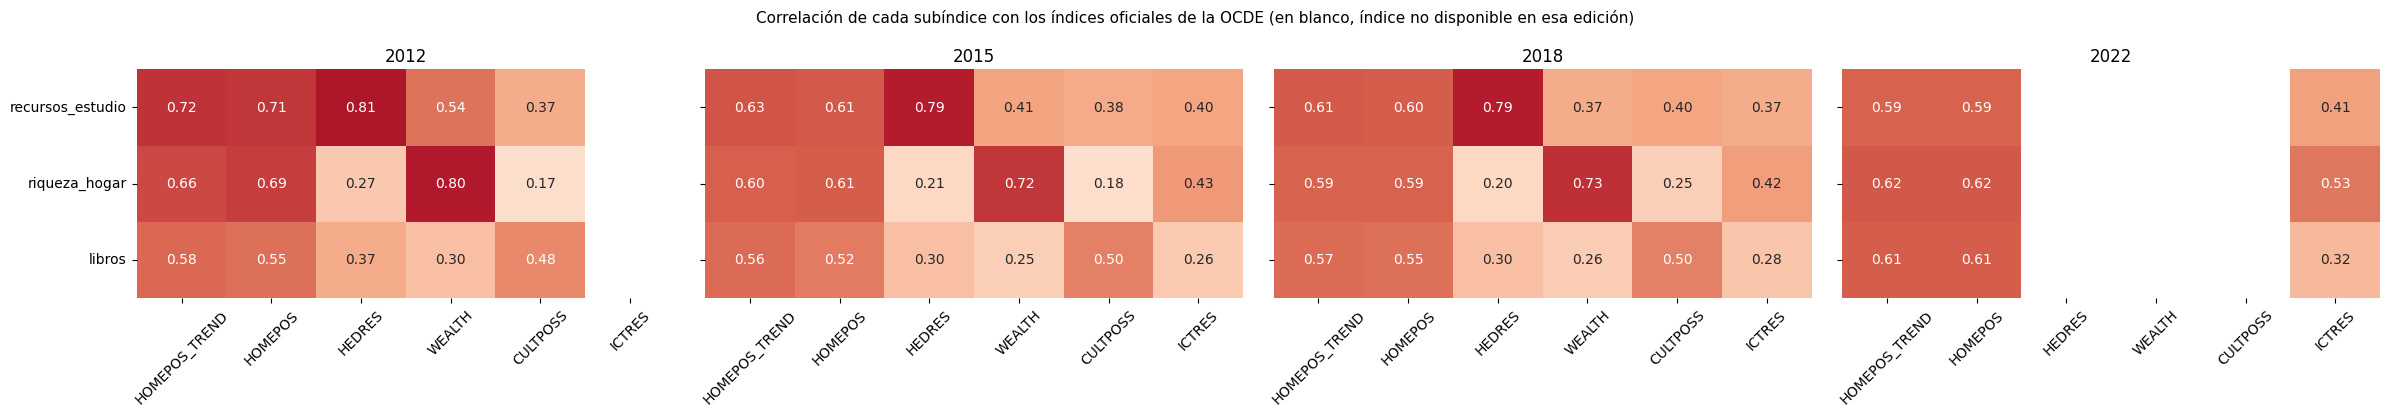

In [6]:
alfas = {}
for subindice, items in SUBINDICES.items():
    if len(items) > 1:
        alfas[subindice] = {edicion: round(alfa_cronbach(grupo, items, 'SENWT'), 3) if not grupo.dropna(subset=items).empty else np.nan
                            for edicion, grupo in alumnos.groupby('year')}
print('Alfa de Cronbach por edición:')
display(pd.DataFrame(alfas).T)

OFICIALES_COMPARADOS = ['HOMEPOS_TREND', 'HOMEPOS', 'HEDRES', 'WEALTH', 'CULTPOSS', 'ICTRES']
fig, ejes = plt.subplots(1, len(EDICIONES_RECURSOS), figsize=(24, 4.2), sharey=True)
for eje, (edicion, grupo) in zip(ejes, alumnos.groupby('year')):
    correlacion = grupo[list(SUBINDICES) + OFICIALES_COMPARADOS].corr().loc[list(SUBINDICES), OFICIALES_COMPARADOS]
    sns.heatmap(correlacion, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='RdBu_r', cbar=False, ax=eje)
    eje.set_title(str(edicion))
    eje.tick_params(axis='x', labelrotation=45)
fig.suptitle('Correlación de cada subíndice con los índices oficiales de la OCDE (en blanco, índice no disponible en esa edición)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_alumno_validacion.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **Cada subíndice se parece sobre todo al índice oficial de su concepto**, y poco a los demás:
  * recursos de estudio con `HEDRES` (recursos educativos del hogar): de 0,79 a 0,81; con `WEALTH` (riqueza), de 0,37 a 0,54;
  * riqueza del hogar con `WEALTH`: de 0,72 a 0,80; con `HEDRES`, de 0,20 a 0,27;
  * libros en casa con `CULTPOSS` (posesiones culturales): de 0,48 a 0,50; con `HEDRES` y `WEALTH`, de 0,25 a 0,37.

  Es decir, los tres subíndices miden cosas distintas y reproducen la separación de la OCDE, también en 2022, cuando la OCDE ya no da subíndices.
* **Con `HOMEPOS_TREND` (todas las posesiones) se parecen los tres** (de 0,56 a 0,72), como se espera de partes de un mismo índice.
* **La coherencia interna es moderada**: el alfa de recursos de estudio va de 0,453 (2022) a 0,525 (2012), y el de riqueza, de 0,490 a 0,546. Son valores modestos porque muchos recursos los tienen casi todos los alumnos y la riqueza solo tiene dos ítems; la correlación con los índices oficiales muestra que, aun así, miden lo que deben.

## 6. Alumnos que se quedan sin subíndice

Un alumno se queda sin subíndice cuando no respondió suficientes ítems (o en su país no se hizo la pregunta). Para cada subíndice, el % de alumnos sin él por país y edición (sin ponderar: es el % de la muestra), qué ítems de recursos de estudio tienen más huecos, y si los alumnos sin subíndice sacan una nota distinta de la de su país, en cada asignatura (media de sus valores plausibles, relativa a la media de su país-edición y ponderada con `SENWT`): si fuera así, quitarlos sesgaría la muestra.

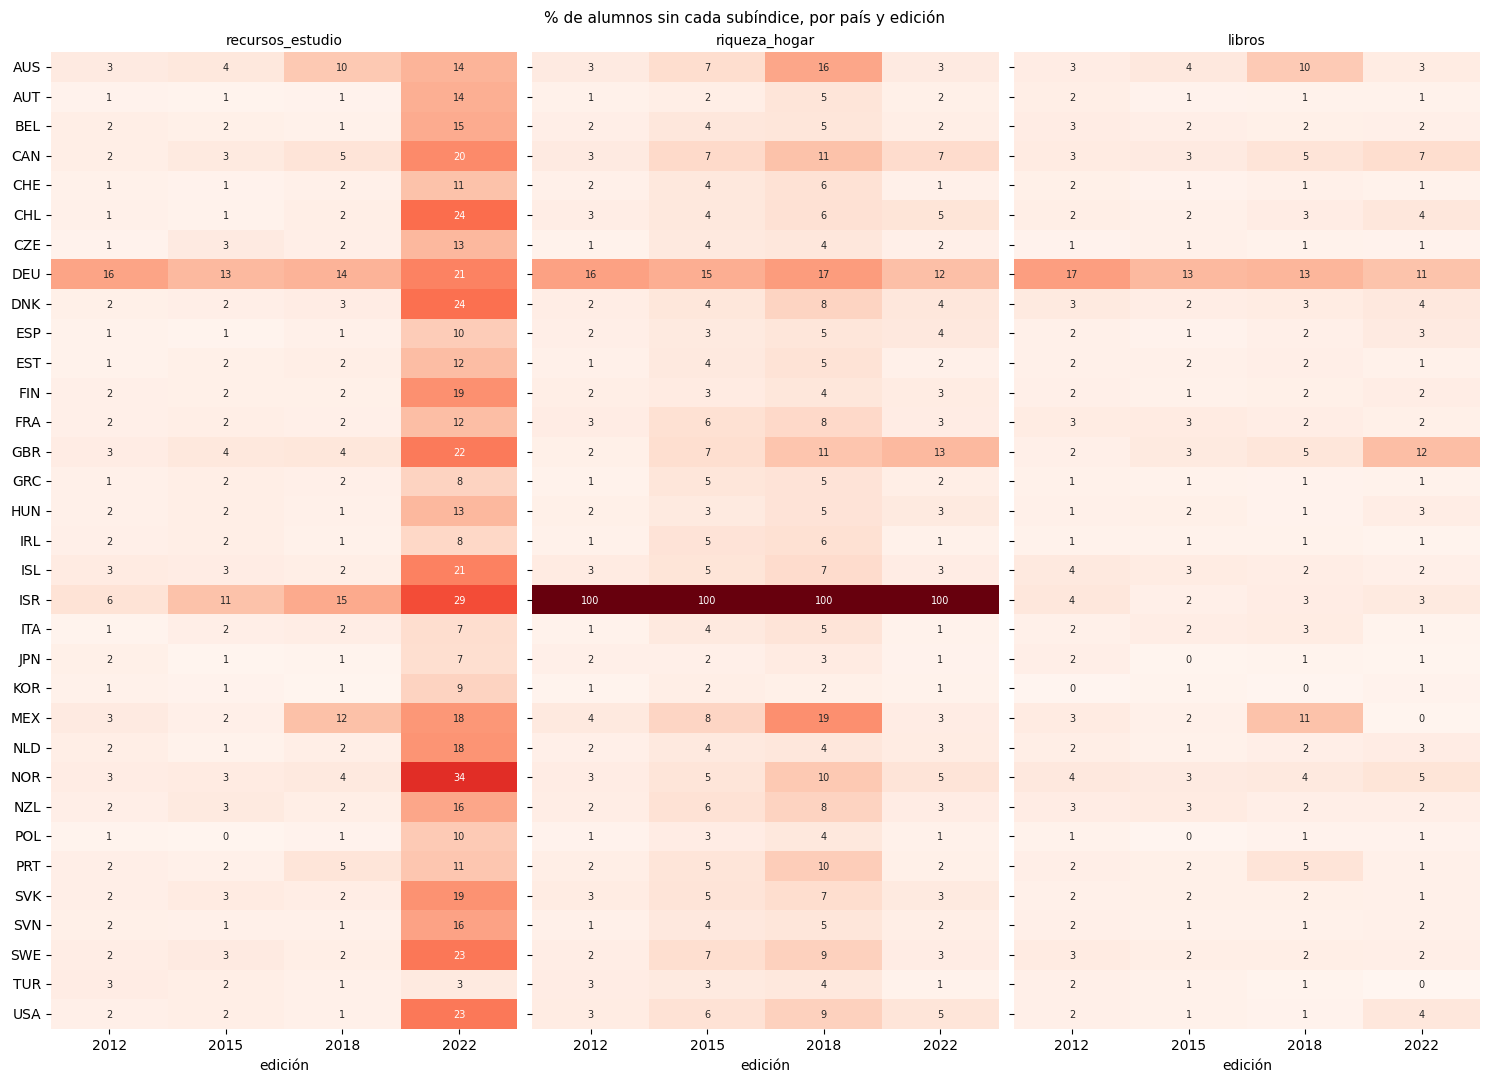

% de alumnos sin dato en cada ítem de recursos de estudio:


,habitacion_propia,ordenador_estudios,internet,libros_ayuda_estudios,libros_tecnicos,diccionario
year,,,,,,
2012,3.6,2.0,2.1,2.6,4.1,2.0
2015,5.0,2.7,2.7,3.1,4.3,2.9
2018,5.5,3.4,3.4,3.6,4.7,3.5
2022,5.6,3.7,3.7,20.3,28.7,18.1


Nota relativa a la media del país-edición:


matemáticas                     lectura                    ciencias              
                      % sin subíndice con subíndice sin subíndice con subíndice sin subíndice con subíndice sin subíndice
recursos_estudio 2012             2.2           1.9         -76.7           2.3         -94.0           2.1         -85.3
                 2015             2.8           1.7         -58.7           2.0         -71.8           1.9         -65.3
                 2018             3.5           1.4         -38.5           1.6         -46.7           1.4         -40.5
                 2022            15.4           7.8         -40.0           9.8         -50.8           8.9         -45.8
riqueza_hogar    2012             4.2           1.6         -27.0           2.0         -34.0           1.8         -30.6
                 2015             7.7           1.9         -22.3           2.2         -26.4           2.0         -24.2
                 2018             9.8           2.1         -18.9           2.6         -23.1           2.2         -19.7
                 2022             6.0           1.4         -20.8           1.7         -25.1           1.5         -21.5
libros           2012             2.4           1.5         -54.8           2.0         -73.7           1.7         -63.6
                 2015             2.3           1.1         -50.2           1.4         -64.6           1.3         -57.0
                 2018             3.2           1.1         -35.3           1.5         -48.5           1.1         -38.2
                 2022             3.2           1.0         -33.3           1.3         -42.8           1.0         -34.6

In [7]:
sin_subindice = alumnos.groupby(['CNT', 'year'])[list(SUBINDICES)].apply(lambda grupo: grupo.isna().mean().mul(100))
fig, ejes = plt.subplots(1, len(SUBINDICES), figsize=(15, 11), sharey=True)
for eje, subindice in zip(ejes, SUBINDICES):
    sns.heatmap(sin_subindice[subindice].unstack('year'), annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=50, cbar=False, ax=eje, annot_kws={'fontsize': 7})
    eje.set_title(subindice, fontsize=10)
    eje.set_xlabel('edición')
    eje.set_ylabel('')
fig.suptitle('% de alumnos sin cada subíndice, por país y edición', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_alumno_sin_subindice.png', dpi=300, bbox_inches='tight')
plt.show()

print('% de alumnos sin dato en cada ítem de recursos de estudio:')
display(alumnos.groupby('year')[SUBINDICES['recursos_estudio']].apply(lambda grupo: grupo.isna().mean().mul(100)).round(1))

# Nota (media de sus valores plausibles) relativa a la media de su país-edición, con y sin subíndice, en cada asignatura (con SENWT)
for asignatura, dominio in ASIGNATURAS.items():
    nota = alumnos[columnas_pv(dominio)].mean(axis=1)
    alumnos[f'nota_relativa_{asignatura}'] = centrar_en_grupos(alumnos.assign(nota=nota), ['nota'], ['CNT', 'year'], peso_col='SENWT')['nota']
filas = {}
for subindice in SUBINDICES:
    for edicion, grupo in alumnos.groupby('year'):
        sin_dato = grupo[subindice].isna()
        fila = {('', '% sin subíndice'): 100 * sin_dato.mean()}
        for asignatura in ASIGNATURAS:
            for etiqueta, alumnos_grupo in (('con subíndice', ~sin_dato), ('sin subíndice', sin_dato)):
                fila[(asignatura, etiqueta)] = np.average(grupo.loc[alumnos_grupo, f'nota_relativa_{asignatura}'], weights=grupo.loc[alumnos_grupo, 'SENWT'])
        filas[(subindice, edicion)] = fila
print('Nota relativa a la media del país-edición:')
pd.DataFrame(filas).T.round(1)

**Qué se ve.**

* **Recursos de estudio**: hasta 2018 faltan para pocos alumnos (en casi todos los países, el 5 % o menos), salvo Alemania (del 13 % al 16 %), Israel (del 6 % al 15 %) y, en 2018, México (12 %) y Australia (10 %). En 2022 faltan bastante más: desde el 3 % de Turquía hasta el 34 % de Noruega, y por encima del 20 % en Israel (29 %), Chile y Dinamarca (24 %), Suecia y Estados Unidos (23 %), Reino Unido (22 %), Alemania e Islandia (21 %) y Canadá (20 %). La causa son las preguntas de tipos de libros, que en 2022 tienen entre el 18,1 % y el 28,7 % de huecos (antes, entre el 2,0 % y el 4,7 %).
* **Riqueza del hogar**: Israel no tiene el subíndice en ninguna edición (no pregunta por los baños). Fuera de eso, faltan sobre todo en Alemania (del 12 % al 17 %) y, en 2018, en México (19 %) y Australia (16 %).
* **Libros en casa**: faltan para pocos alumnos, salvo en Alemania (del 11 % al 17 %).
* **Los alumnos sin subíndice sacan bastante menos nota que la media de su país, en las tres asignaturas**: según la edición, los que no tienen recursos de estudio, entre 38,5 y 76,7 puntos menos en matemáticas, entre 46,7 y 94,0 en lectura y entre 40,5 y 85,3 en ciencias; los que no tienen riqueza, entre 18,9 y 34,0 menos, y los que no tienen libros, entre 33,3 y 73,7. La diferencia es mayor en lectura. Como con el `ESCS` (hallazgos de `01_EDA_por_edicion`), los huecos no son al azar: quitar a esos alumnos sesgaría la muestra hacia los mejores. Los recursos de estudio, variable de interés, no se imputan; en los controles se añade un indicador de «sin dato» (`01_EDA_variables_modelo`).

## 7. Evolución dentro de cada país

La media de cada subíndice por país y edición (ponderada con `W_FSTUWT`, para que represente a los alumnos de 15 años del país), y cuánto cambia cada país entre 2012 y 2022.

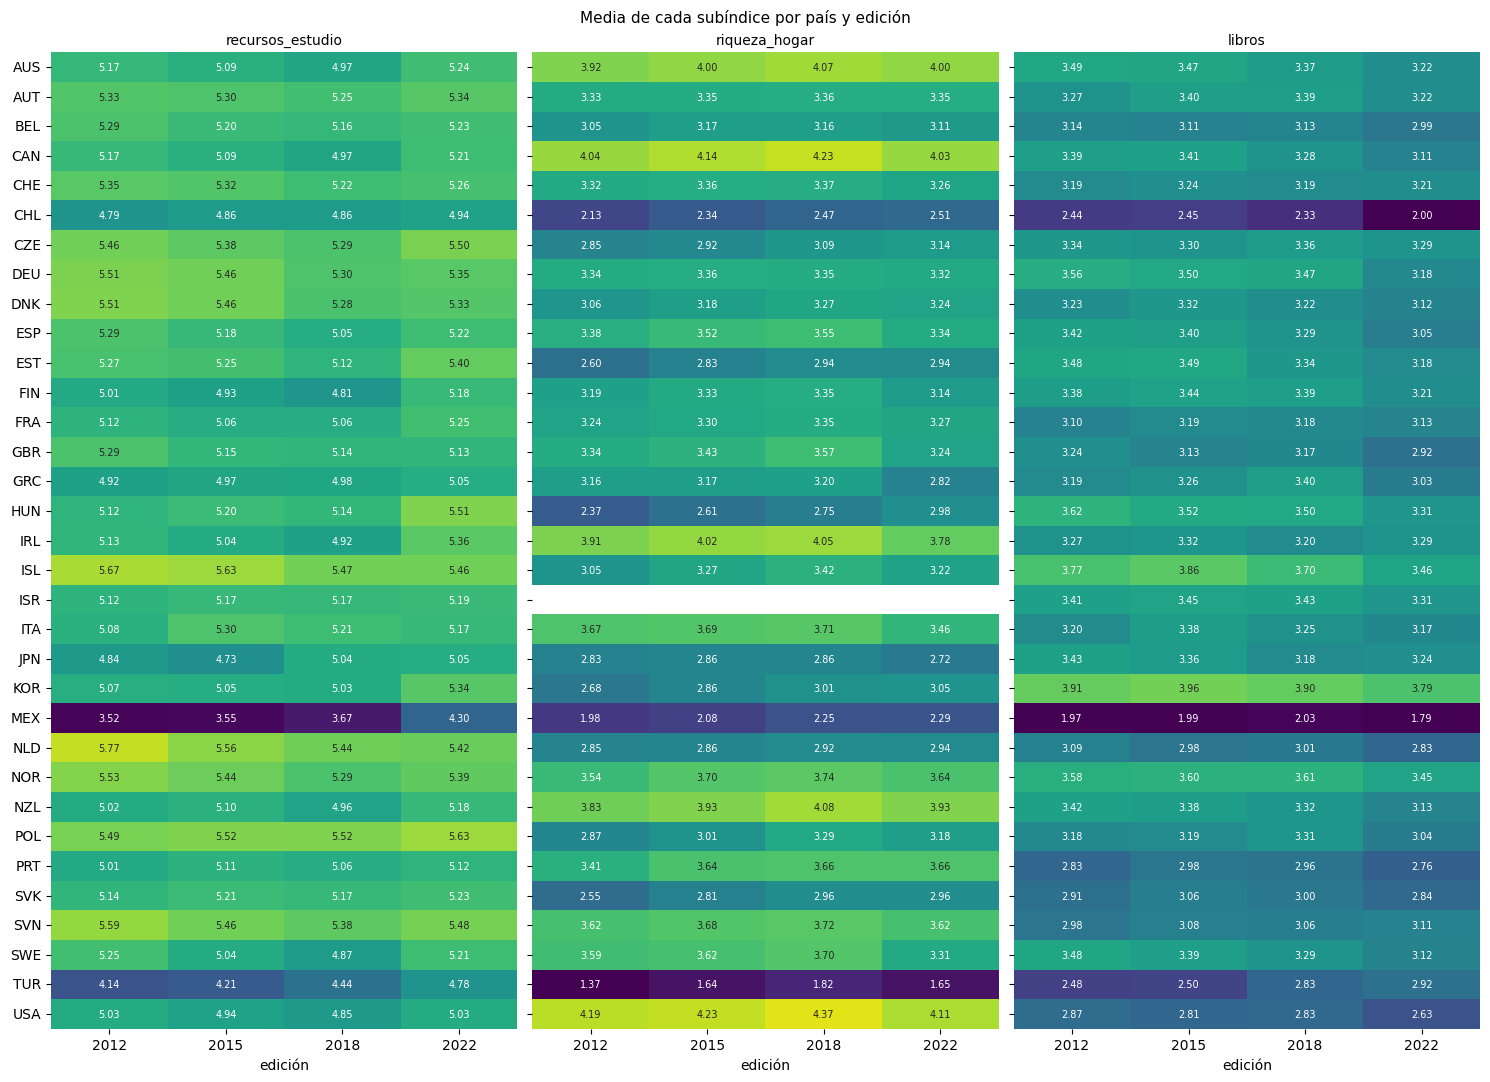

,cambio medio 2012-2022,país que más sube,país que más baja,desviación entre países en 2012,desviación entre países en 2022
recursos_estudio,0.075162,MEX (+0.78),NLD (-0.35),0.420869,0.241892
riqueza_hogar,0.091564,HUN (+0.61),GRC (-0.35),0.622891,0.511356
libros,-0.157239,TUR (+0.44),CHL (-0.44),0.387641,0.372424


In [8]:
medias_pais = agregar_media_ponderada(alumnos, list(SUBINDICES), claves=['CNT', 'year'], peso_col='W_FSTUWT')
fig, ejes = plt.subplots(1, len(SUBINDICES), figsize=(15, 11), sharey=True)
ESCALAS = {'recursos_estudio': (3.5, 6), 'riqueza_hogar': (1.5, 4.5), 'libros': (2, 4.5)}
for eje, subindice in zip(ejes, SUBINDICES):
    tabla = medias_pais.pivot(index='CNT', columns='year', values=subindice)
    sns.heatmap(tabla, annot=True, fmt='.2f', cmap='viridis', vmin=ESCALAS[subindice][0], vmax=ESCALAS[subindice][1], cbar=False, ax=eje, annot_kws={'fontsize': 7})
    eje.set_title(subindice, fontsize=10)
    eje.set_xlabel('edición')
    eje.set_ylabel('')
fig.suptitle('Media de cada subíndice por país y edición', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_alumno_evolucion_pais.png', dpi=300, bbox_inches='tight')
plt.show()

cambio = medias_pais.pivot(index='CNT', columns='year', values=list(SUBINDICES))
resumen_cambio = {}
for subindice in SUBINDICES:
    diferencia = (cambio[(subindice, 2022)] - cambio[(subindice, 2012)]).dropna()
    resumen_cambio[subindice] = {'cambio medio 2012-2022': diferencia.mean(), 'país que más sube': f'{diferencia.idxmax()} ({diferencia.max():+.2f})',
                                 'país que más baja': f'{diferencia.idxmin()} ({diferencia.min():+.2f})',
                                 'desviación entre países en 2012': cambio[(subindice, 2012)].std(), 'desviación entre países en 2022': cambio[(subindice, 2022)].std()}
pd.DataFrame(resumen_cambio).T

**Qué se ve.**

* **Los subíndices apenas cambian dentro de cada país**: de media, entre 2012 y 2022 los recursos de estudio suben 0,08 puntos (sobre 6), la riqueza 0,09 y los libros bajan 0,16. Los cambios más grandes son la subida de México en recursos de estudio (+0,78) y en riqueza la de Hungría (+0,61); los libros bajan sobre todo en Chile (−0,44).
* **Cautela al comparar niveles entre países**: algunos ítems de recursos de estudio son más raros o más comunes en ciertos países por motivos que no tienen que ver con los recursos (por ejemplo, el diccionario es mucho más común de lo esperable en México y mucho más raro en los países nórdicos; sección 12). Parte de las diferencias de nivel entre países depende de qué ítems se usan. Los cambios dentro de un mismo país y las comparaciones entre sus alumnos no se ven afectados.
* **En recursos de estudio los países se acercan**: la desviación entre las medias de los países baja de 0,42 en 2012 a 0,24 en 2022, sobre todo porque los países con menos recursos (México) los ganan. En riqueza baja algo (de 0,62 a 0,51) y en libros casi nada (de 0,39 a 0,37).

## 8. Dónde está la variación de cada subíndice

Para saber si un subíndice puede aportar señal al modelo hay que ver a qué nivel varía. Su varianza (con las cuatro ediciones juntas y cada país-edición pesando igual, con `SENWT`) se reparte en cuatro partes anidadas (`reparto_varianza` de `src/pisa_estadisticas.py`): entre países, entre ediciones de un mismo país, entre centros de un mismo país-edición y entre alumnos de un mismo centro. Para comparar, lo mismo con la nota de cada asignatura (con cada valor plausible por separado) y el `ESCS`.

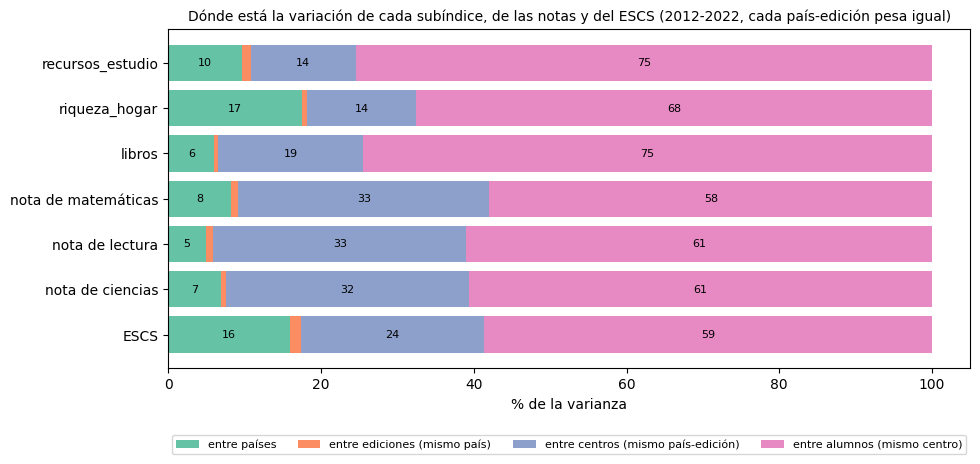

,entre países,entre ediciones (mismo país),entre centros (mismo país-edición),entre alumnos (mismo centro)
recursos_estudio,9.7,1.1,13.7,75.5
riqueza_hogar,17.5,0.7,14.3,67.5
libros,6.0,0.5,18.9,74.5
nota de matemáticas,8.3,0.9,32.9,57.9
nota de lectura,4.9,1.0,33.1,61.0
nota de ciencias,6.9,0.6,31.8,60.6
ESCS,15.9,1.4,23.9,58.7


In [9]:
NIVELES = {'entre países': ['CNT'], 'entre ediciones (mismo país)': ['CNT', 'year'], 'entre centros (mismo país-edición)': ['CNT', 'year', 'CNTSCHID']}
RESIDUO = 'entre alumnos (mismo centro)'


def reparto_alumnos(datos, columna):
    return reparto_varianza(datos, columna, NIVELES, RESIDUO, peso_col='SENWT')


# La nota, con cada valor plausible por separado (los cinco de 2012 en todas las ediciones)
reparto = pd.DataFrame({**{subindice: reparto_alumnos(alumnos, subindice) for subindice in SUBINDICES},
                        **{f'nota de {asignatura}': estimar_con_pv(alumnos, dominio, reparto_alumnos) for asignatura, dominio in ASIGNATURAS.items()},
                        'ESCS': reparto_alumnos(alumnos, 'ESCS_TREND')}).T
fig, ax = plt.subplots(figsize=(10, 4.8))
izquierda = np.zeros(len(reparto))
for nivel, color in zip(reparto.columns, sns.color_palette('Set2', n_colors=len(reparto.columns))):
    barras = ax.barh(reparto.index[::-1], reparto[nivel][::-1], left=izquierda[::-1], color=color, label=nivel)
    ax.bar_label(barras, labels=[f'{valor:.0f}' if valor >= 4 else '' for valor in reparto[nivel][::-1]], label_type='center', fontsize=8)
    izquierda += reparto[nivel].to_numpy()
ax.set_xlabel('% de la varianza')
ax.set_title('Dónde está la variación de cada subíndice, de las notas y del ESCS (2012-2022, cada país-edición pesa igual)', fontsize=10)
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncols=4)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_alumno_reparto_varianza.png', dpi=300, bbox_inches='tight')
plt.show()
reparto.round(1)

**Qué se ve.**

* **Los subíndices varían sobre todo entre alumnos del mismo centro**: el 75,5 % de la varianza de los recursos de estudio, el 67,5 % de la de la riqueza y el 74,5 % de la de los libros, más que las notas (del 57,9 % en matemáticas al 61,0 % en lectura) o el `ESCS` (58,7 %). Entre centros del mismo país-edición está entre el 13,7 % y el 18,9 %, menos que en las notas (del 31,8 % al 33,1 %).
* **Entre ediciones de un mismo país casi no hay variación**: del 0,5 % al 1,1 % en los subíndices (y del 0,6 % al 1,0 % en las notas). La señal temporal de estos recursos (si cambian en un país y cambia su nota) es mínima; su información está en las diferencias entre alumnos.
* **Entre países**: del 6,0 % (libros) al 17,5 % (riqueza), frente al 4,9-8,3 % de las notas.

Para el modelo, esto apoya trabajar con datos por alumno: agregar por centro o por país borraría entre dos tercios y tres cuartos de la variación de los recursos del hogar.

## 9. Relación con la nota, descontando el origen social

Todo se mide dentro de cada país-edición (cada variable se centra en la media de su país-edición, `centrar_en_grupos`), para comparar alumnos del mismo país y no países entre sí. El origen social se mide sin las posesiones del hogar, para no solaparse con los subíndices: ocupación (`HISEI_TREND`) y educación de los padres (`PAREDINT_TREND`), en sus versiones comparables entre ediciones. Las correlaciones y regresiones con la nota se calculan con cada valor plausible de matemáticas, lectura y ciencias y se promedian.

* **Correlaciones** entre subíndices, origen social y nota, por edición.
* **Regresión dentro de cada país-edición** (`regresion_dentro_de_grupos`, ponderada con `SENWT`): cuántos puntos de nota se asocian a una desviación típica de cada subíndice, solo y junto a los demás y al origen social. Es descriptiva: muestra asociaciones, no efectos causales (eso corresponde al modelo).

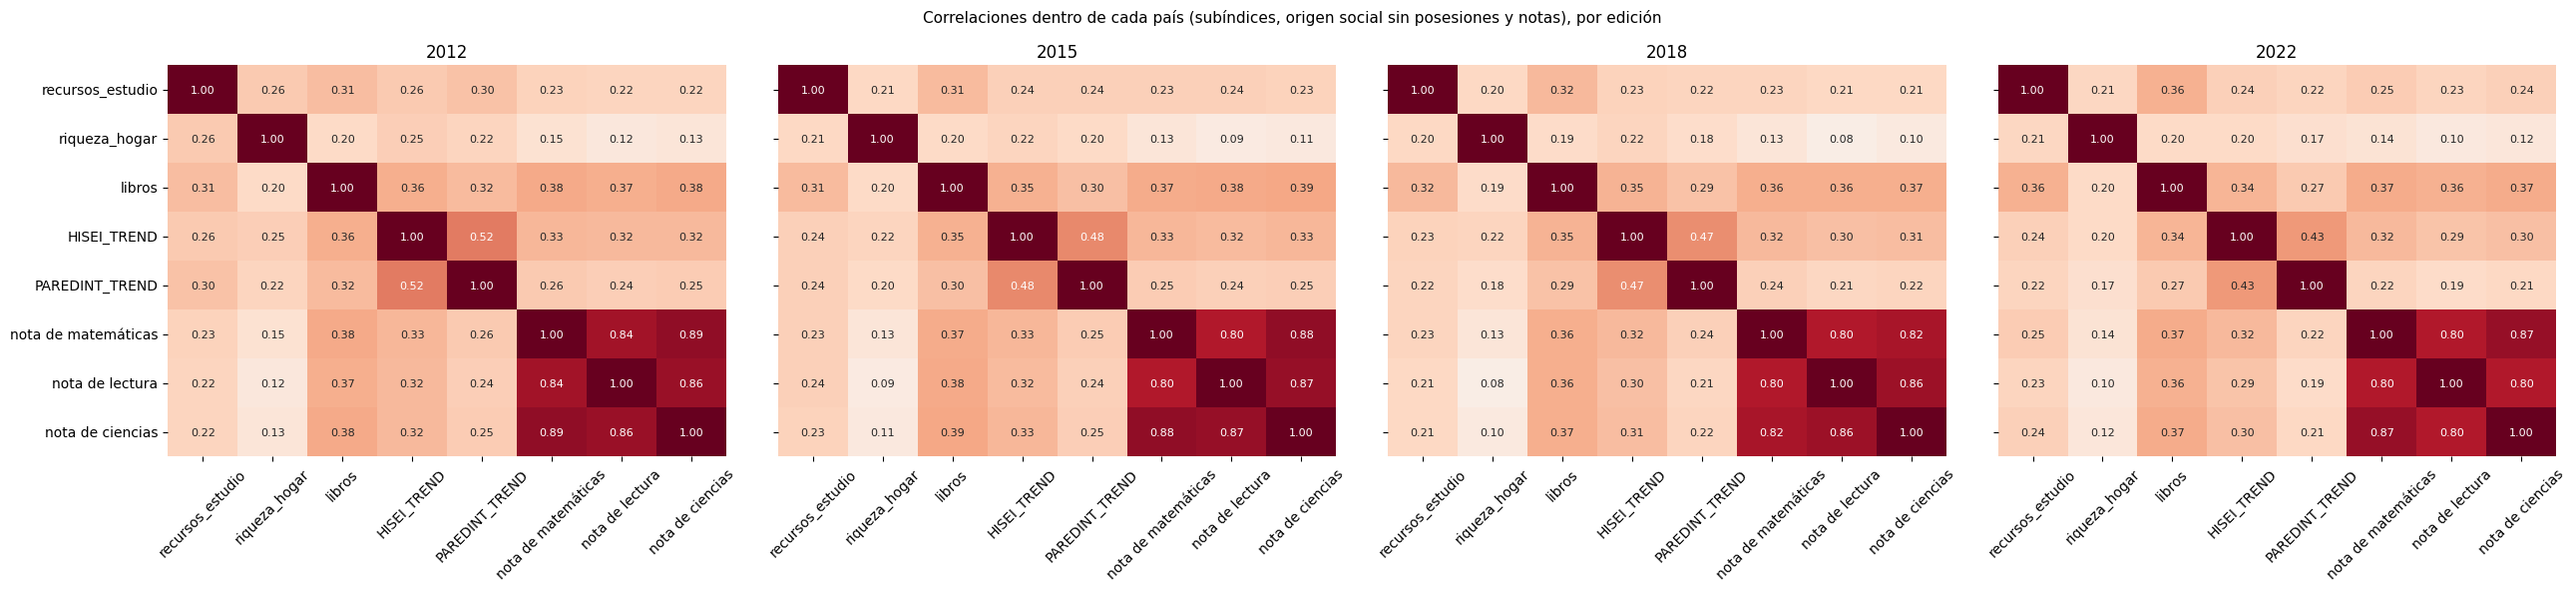

2012: 257029 alumnos con todas las variables


2015: 203289 alumnos con todas las variables


2018: 225666 alumnos con todas las variables


2022: 205419 alumnos con todas las variables


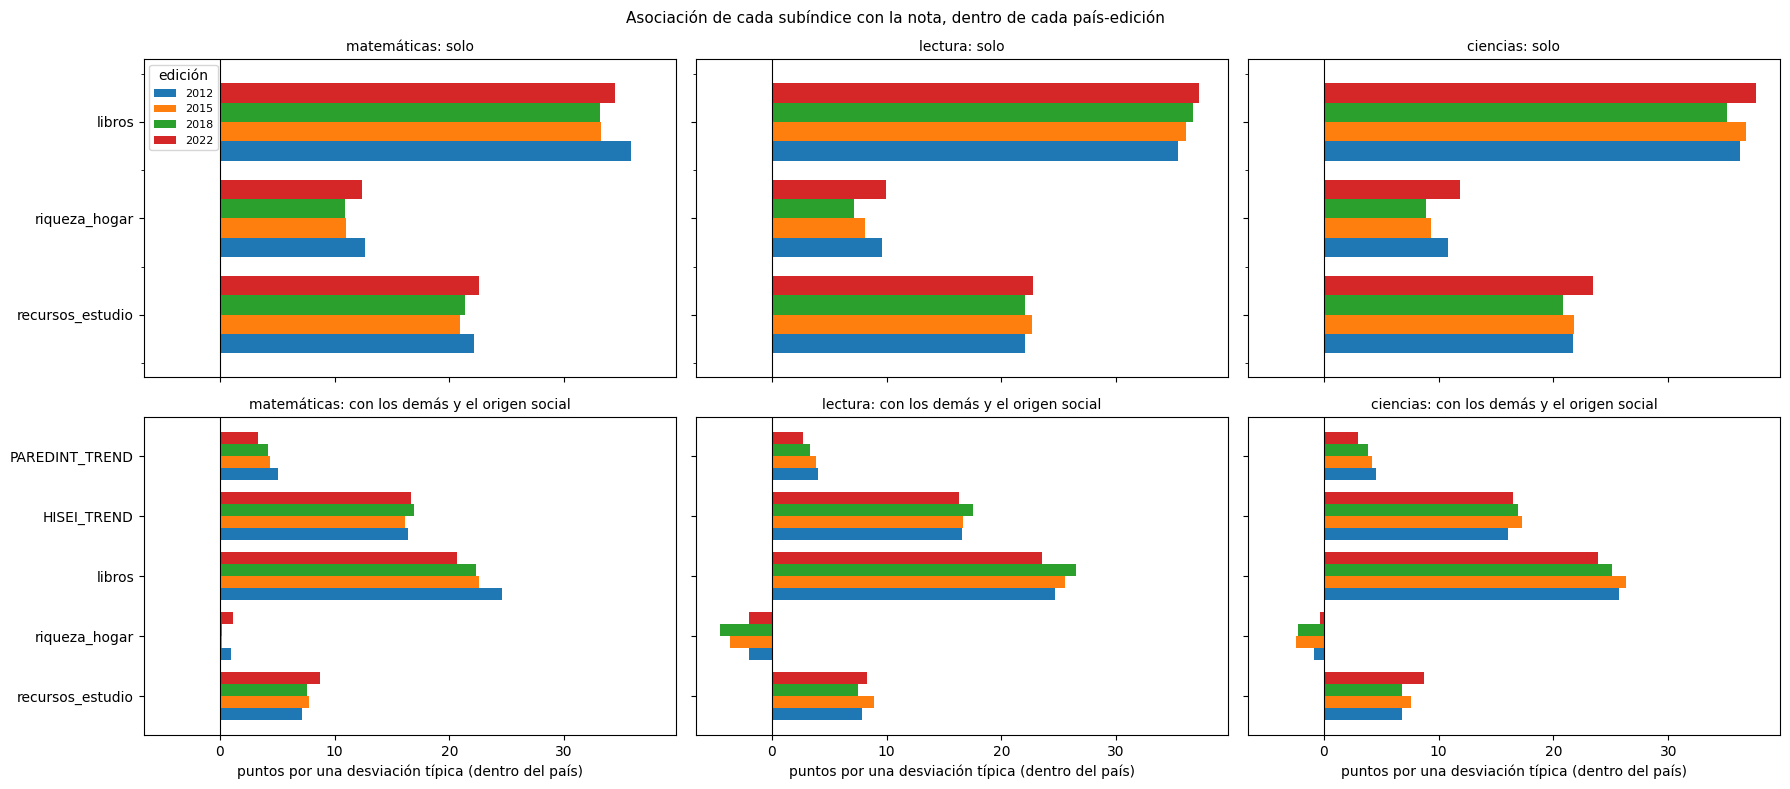

asignatura                                        ciencias                   lectura                   matemáticas                  
edición                                               2012  2015  2018  2022    2012  2015  2018  2022        2012  2015  2018  2022
modelo                           variable                                                                                           
con los demás y el origen social HISEI_TREND          16.0  17.3  16.9  16.5    16.6  16.7  17.6  16.3        16.4  16.1  16.9  16.6
                                 PAREDINT_TREND        4.6   4.2   3.8   3.0     4.0   3.8   3.3   2.7         5.1   4.4   4.2   3.3
                                 libros               25.7  26.4  25.1  23.9    24.7  25.5  26.5  23.5        24.6  22.6  22.3  20.6
                                 recursos_estudio      6.8   7.6   6.8   8.7     7.8   8.9   7.5   8.3         7.2   7.8   7.6   8.8
                                 riqueza_hogar        -0.9  -2.4  -2.3  -0.3    -2.0  -3.7  -4.5  -2.0         1.0   0.2   0.2   1.1
solo                             libros               36.2  36.8  35.2  37.6    35.4  36.0  36.7  37.2        35.8  33.2  33.1  34.5
                                 recursos_estudio     21.7  21.8  20.9  23.5    22.1  22.6  22.0  22.7        22.1  20.9  21.4  22.6
                                 riqueza_hogar        10.8   9.4   8.9  11.8     9.6   8.1   7.2  10.0        12.7  11.0  10.9  12.4

In [10]:
VARIABLES_NOTA = list(SUBINDICES) + ['HISEI_TREND', 'PAREDINT_TREND']


def correlaciones(datos, columna_matematicas):
    """Correlaciones dentro de cada país de `VARIABLES_NOTA` y la nota, con el valor plausible `columna_matematicas`
    y los del mismo número en lectura y ciencias."""
    columnas_nota = {columna_matematicas.replace('MATH', dominio): f'nota de {asignatura}' for asignatura, dominio in ASIGNATURAS.items()}
    return centrar_en_grupos(datos, VARIABLES_NOTA + list(columnas_nota), ['CNT'], peso_col='SENWT').rename(columns=columnas_nota).corr()


fig, ejes = plt.subplots(1, len(EDICIONES_RECURSOS), figsize=(26, 6), sharey=True)
for eje, (edicion, grupo) in zip(ejes, alumnos.groupby('year')):
    sns.heatmap(estimar_con_pv(grupo, 'MATH', correlaciones), annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='RdBu_r', cbar=False, ax=eje, annot_kws={'fontsize': 8})
    eje.set_title(str(edicion))
    eje.tick_params(axis='x', labelrotation=45)
fig.suptitle('Correlaciones dentro de cada país (subíndices, origen social sin posesiones y notas), por edición', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_alumno_correlaciones_nota.png', dpi=300, bbox_inches='tight')
plt.show()

# Puntos de nota por desviación típica: cada subíndice solo, y todos juntos con el origen social, en cada asignatura
CONTROLES_ORIGEN = ['HISEI_TREND', 'PAREDINT_TREND']
MODELOS = ['solo', 'con los demás y el origen social']
filas = []
for asignatura, dominio in ASIGNATURAS.items():
    for edicion, grupo in alumnos.groupby('year'):
        for subindice in SUBINDICES:
            solo = estimar_con_pv(grupo, dominio, lambda datos, columna: regresion_dentro_de_grupos(datos, columna, [subindice], ['CNT'], peso_col='SENWT'))
            filas.append({'asignatura': asignatura, 'edición': edicion, 'variable': subindice, 'modelo': MODELOS[0],
                          'puntos por desviación típica': solo.loc[subindice, 'por desviación típica']})
        juntos = estimar_con_pv(grupo, dominio, lambda datos, columna: regresion_dentro_de_grupos(datos, columna, list(SUBINDICES) + CONTROLES_ORIGEN, ['CNT'], peso_col='SENWT'))
        for variable in list(SUBINDICES) + CONTROLES_ORIGEN:
            filas.append({'asignatura': asignatura, 'edición': edicion, 'variable': variable, 'modelo': MODELOS[1],
                          'puntos por desviación típica': juntos.loc[variable, 'por desviación típica']})
        if asignatura == 'matemáticas':
            print(f"{edicion}: {int(juntos['filas'].iloc[0])} alumnos con todas las variables")
asociacion = pd.DataFrame(filas)

fig, ejes = plt.subplots(len(MODELOS), len(ASIGNATURAS), figsize=(18, 8), sharey='row', sharex=True)
for fila_ejes, modelo in zip(ejes, MODELOS):
    for eje, asignatura in zip(fila_ejes, ASIGNATURAS):
        tabla = asociacion[(asociacion['modelo'] == modelo) & (asociacion['asignatura'] == asignatura)].pivot(index='variable', columns='edición', values='puntos por desviación típica')
        tabla = tabla.reindex([variable for variable in list(SUBINDICES) + CONTROLES_ORIGEN if variable in tabla.index])
        tabla.plot.barh(ax=eje, width=0.8, legend=(eje is ejes[0][0]))
        eje.axvline(0, color='black', lw=0.8)
        eje.set_title(f'{asignatura}: {modelo}', fontsize=10)
        eje.set_ylabel('')
        eje.set_xlabel('puntos por una desviación típica (dentro del país)')
ejes[0][0].legend(fontsize=8, title='edición')
fig.suptitle('Asociación de cada subíndice con la nota, dentro de cada país-edición', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_alumno_asociacion_nota.png', dpi=300, bbox_inches='tight')
plt.show()
asociacion.pivot_table(index=['modelo', 'variable'], columns=['asignatura', 'edición'], values='puntos por desviación típica').round(1)

**Qué se ve.** Las tres asignaturas se comportan casi igual (sus notas tienen correlaciones de 0,80 a 0,89 entre sí, dentro de cada país; `01_EDA_notas_asignatura`).

* **Correlaciones con las notas dentro de cada país**: los libros en casa son los que más se relacionan (de 0,36 a 0,39), más que la ocupación de los padres (0,29-0,33) y su educación (0,19-0,26); los recursos de estudio, de 0,21 a 0,25, y la riqueza, de 0,08 a 0,15.
* **Una desviación típica más de cada subíndice, por sí solo**, se asocia a entre 33,1 y 37,6 puntos más de nota en libros, entre 20,9 y 23,5 en recursos de estudio y entre 7,2 y 12,7 en riqueza, según la asignatura y la edición.
* **Con los demás subíndices y el origen social en el mismo modelo**:
  * los libros siguen asociados a entre 20,6 y 26,5 puntos;
  * los recursos de estudio, a entre 6,8 y 8,9 puntos: algo más de un tercio de su asociación inicial, estable entre ediciones y asignaturas;
  * la riqueza desaparece (entre −4,5 y 1,1 puntos; algo negativa en lectura y ciencias): lo que tenía de relación con la nota lo explican el origen social y los demás subíndices, lo que encaja con que sea origen social y no un recurso.
* **El origen social sin posesiones** (sobre todo la ocupación de los padres, de 16,1 a 17,6 puntos) se mantiene en todas las ediciones y asignaturas.

Son asociaciones descriptivas con entre 203.289 y 257.029 alumnos por edición (los que tienen todas las variables), no efectos causales.

## 10. Libros en casa: ¿recurso o capital cultural?

El número de libros en casa puede leerse de dos maneras: como un recurso para estudiar (hay libros a mano) o como capital cultural de la familia, es decir, parte del origen social. Para el modelo la diferencia importa: un recurso es una variable de interés; el origen social, un control. Un indicio es con qué se relaciona más dentro de cada país: con la educación y la ocupación de los padres (origen social) o con los recursos de estudio. La tabla resume las correlaciones de la sección 9, de media entre ediciones.

In [11]:
correlaciones = []
for edicion, grupo in alumnos.groupby('year'):
    centradas = centrar_en_grupos(grupo, VARIABLES_NOTA, ['CNT'], peso_col='SENWT')
    correlaciones.append(centradas.corr().loc[list(SUBINDICES), ['PAREDINT_TREND', 'HISEI_TREND'] + list(SUBINDICES)])
media_correlaciones = sum(correlaciones) / len(correlaciones)
media_correlaciones.round(2)

,PAREDINT_TREND,HISEI_TREND,recursos_estudio,riqueza_hogar,libros
recursos_estudio,0.24,0.24,1.00,0.22,0.33
riqueza_hogar,0.19,0.22,0.22,1.00,0.20
libros,0.29,0.35,0.33,0.20,1.00


**Qué se ve.** Dentro de cada país, los libros en casa se relacionan más con el origen social que los recursos de estudio: 0,35 con la ocupación de los padres y 0,29 con su educación, frente a 0,24 y 0,24 de los recursos de estudio. También se relacionan con los recursos de estudio (0,33), más que la riqueza (0,20).

**Decisión**: los libros en casa se tratan como **capital cultural de la familia**, es decir, origen social y por tanto control, por tres razones: están más ligados a la ocupación y la educación de los padres que los recursos de estudio; la literatura de PISA los trata así (forman parte de las posesiones culturales, `CULTPOSS`, en la sección 5 se parecen sobre todo a ese índice); y no son un recurso que un centro o una política pueda dar al alumno. Los libros útiles para estudiar (de ayuda, técnicos, diccionario) ya están en el subíndice de recursos de estudio. Como comprobación, el modelo puede estimarse también tratando los libros como recurso.

## 11. Recursos del centro vistos por el alumno

Dos índices del cuestionario del alumno describen recursos de su centro: el apoyo del profesor (`TEACHSUP`) y las TIC disponibles en el centro (`ICTSCH`). Antes de usarlos hay que ver si miden lo mismo en todas las ediciones (etiquetas del diccionario de columnas y media), cuántos alumnos tienen dato por país, si varían sobre todo entre centros (recurso del centro) o entre alumnos del mismo centro (percepción de cada alumno), y cómo se relacionan con la nota dentro de cada país.

EDICION,2012,2015,2018,2022
COLUMNA,,,,
ICTSCH,ICT Availability at School,ICT available at School Index (Sum),ICT available at school,ICT availability at school (WLE)
TEACHSUP,Teacher Support,Teacher support in a science classes of students choice (WLE),Teacher support in test language lessons (WLE),Mathematics Teacher Support (WLE)


Media por edición (sin ponderar):


,TEACHSUP,ICTSCH
year,,
2012,0.07,-0.05
2015,0.02,6.10
2018,0.02,6.26
2022,-0.06,-0.01


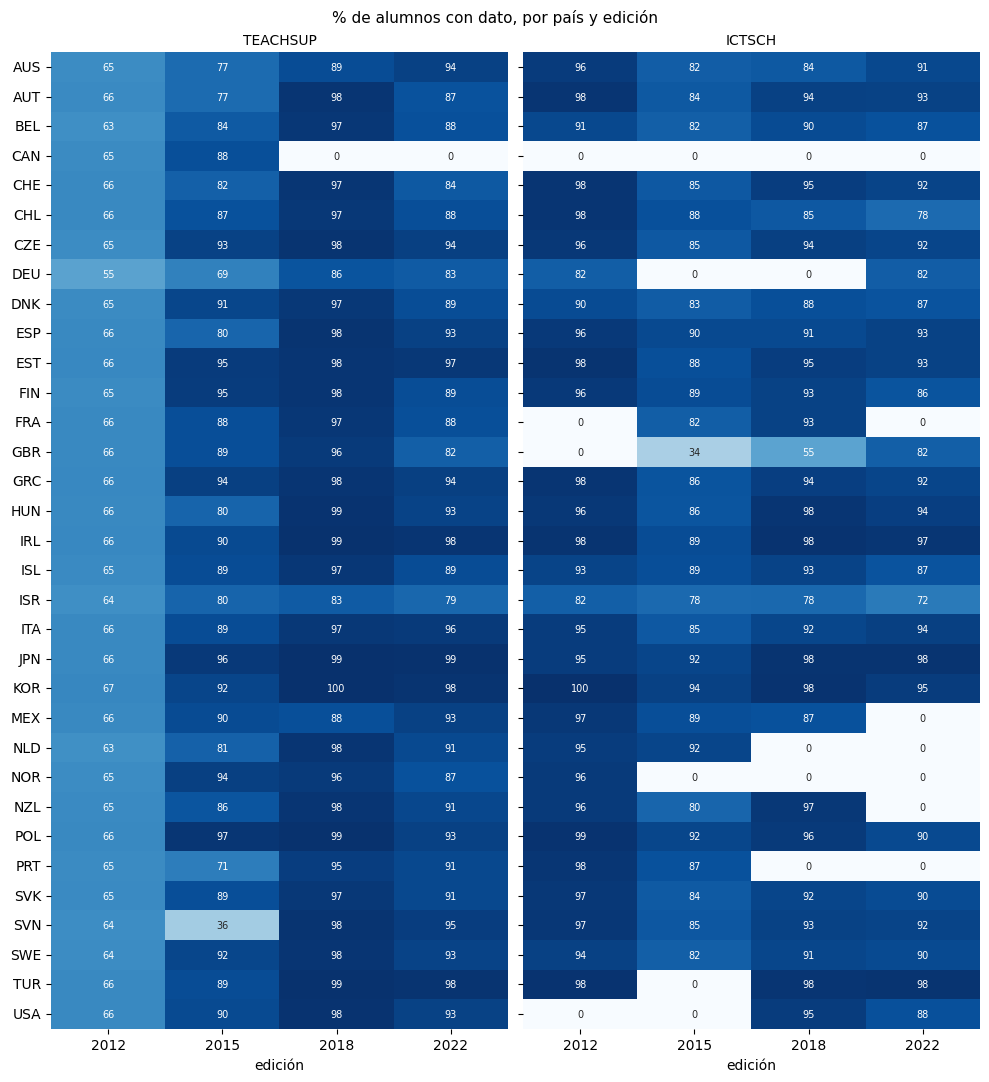

,,entre países,entre centros,entre alumnos del centro,r con matemáticas (dentro del país),r con lectura (dentro del país),r con ciencias (dentro del país)
TEACHSUP,2012,7.5,13.5,79.0,0.018,0.008,0.013
ICTSCH,2012,12.4,15.4,72.2,-0.045,-0.069,-0.055
TEACHSUP,2015,6.3,10.3,83.5,-0.006,-0.003,0.008
ICTSCH,2015,11.3,14.0,74.7,-0.055,-0.071,-0.066
TEACHSUP,2018,6.8,10.0,83.2,-0.002,0.025,0.011
ICTSCH,2018,9.5,12.7,77.8,-0.027,-0.055,-0.045
TEACHSUP,2022,5.8,10.2,83.9,0.049,0.047,0.049
ICTSCH,2022,1.2,6.5,92.3,0.029,0.037,0.031


In [12]:
INDICES_CENTRO_ALUMNO = ['TEACHSUP', 'ICTSCH']
etiquetas = diccionario[diccionario['COLUMNA'].isin(INDICES_CENTRO_ALUMNO) & (diccionario['TABLA'] == 'estudiantes')].pivot(index='COLUMNA', columns='EDICION', values='ETIQUETA')
with pd.option_context('display.max_colwidth', 70):
    display(etiquetas)
print('Media por edición (sin ponderar):')
display(alumnos.groupby('year')[INDICES_CENTRO_ALUMNO].mean().round(2))

con_dato = alumnos.groupby(['CNT', 'year'])[INDICES_CENTRO_ALUMNO].apply(lambda grupo: grupo.notna().mean().mul(100))
fig, ejes = plt.subplots(1, 2, figsize=(10, 11), sharey=True)
for eje, indice in zip(ejes, INDICES_CENTRO_ALUMNO):
    sns.heatmap(con_dato[indice].unstack('year'), annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, cbar=False, ax=eje, annot_kws={'fontsize': 7})
    eje.set_title(indice, fontsize=10)
    eje.set_xlabel('edición')
    eje.set_ylabel('')
fig.suptitle('% de alumnos con dato, por país y edición', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_alumno_indices_centro.png', dpi=300, bbox_inches='tight')
plt.show()

filas = {}
for edicion, grupo in alumnos.groupby('year'):
    for indice in INDICES_CENTRO_ALUMNO:
        reparto_indice = reparto_varianza(grupo, indice, {'entre países': ['CNT'], 'entre centros': ['CNT', 'CNTSCHID']}, 'entre alumnos del centro', peso_col='SENWT')
        filas[(indice, edicion)] = {**reparto_indice.round(1).to_dict(),
                                    **{f'r con {asignatura} (dentro del país)': round(estimar_con_pv(grupo, dominio, lambda datos, columna: centrar_en_grupos(datos, [indice, columna], ['CNT'], peso_col='SENWT').corr().iloc[0, 1]), 3)
                                       for asignatura, dominio in ASIGNATURAS.items()}}
pd.DataFrame(filas).T

**Qué se ve.**

* **No miden lo mismo en todas las ediciones**:
  * el apoyo del profesor se refiere a matemáticas en 2012 y 2022, a ciencias en 2015 y a lengua en 2018;
  * las TIC del centro son un índice estandarizado en 2012 y 2022 (media de −0,05 y −0,01) y una suma en 2015 y 2018 (media de 6,10 y 6,26).
* **Faltan muchos datos**: el apoyo del profesor solo lo tiene en torno al 65 % de los alumnos de cada país en 2012 (pregunta rotada) y falta entero en Canadá en 2018 y 2022; las TIC del centro faltan enteras en Canadá en las cuatro ediciones y en otros países en alguna edición (Alemania, Francia, Reino Unido, México, Países Bajos, Noruega, Nueva Zelanda, Portugal, Turquía y Estados Unidos).
* **Son sobre todo percepciones de cada alumno, no recursos del centro**: entre el 72 % y el 92 % de su varianza está entre alumnos del mismo centro, y solo entre el 6,5 % y el 15,4 %, entre centros.
* **No se relacionan con la nota**: la correlación dentro de cada país va de −0,071 a 0,049 en las tres asignaturas.

No sirven como recursos del centro comparables entre ediciones. El centro entra en el análisis a través de su perfil (`00_Pipeline_generacion_estratos`).

## 12. Comprobación con IRT

El subíndice de recursos de estudio es una suma de ítems. La OCDE construye sus índices con IRT (teoría de respuesta al ítem): cada ítem tiene una dificultad (lo «raro» que es tenerlo) y cada alumno un nivel, y la probabilidad de tener un ítem depende de la diferencia entre los dos (modelo de Rasch). Para 2012-2018 la suma ya se comparó con el índice IRT oficial (`HEDRES`, sección 5); en 2022 no hay índice oficial, y es la edición en la que cambian preguntas y más alumnos responden solo parte de los ítems. Tres comprobaciones (`calibrar_rasch` y `puntuacion_eap` en `src/recursos_alumno.py`):

1. **Dificultad de cada ítem**, con las cuatro ediciones juntas y con cada edición por separado (muestras de 40.000 alumnos con probabilidad proporcional a `SENWT`). Cada estimación por edición fija en 0 el nivel medio de sus alumnos, así que para comparar ediciones se mira la dificultad de cada ítem respecto a la media de los ítems de su edición: si un ítem se vuelve mucho más fácil o difícil que los demás en 2022, la pregunta puede estar midiendo otra cosa (funcionamiento diferencial del ítem).
2. **Puntuación IRT de cada alumno** con las dificultades de las cuatro ediciones juntas, usando solo los ítems que respondió (sin prorratear), para los mismos alumnos que tienen la suma, y su parecido con la suma: con todos los alumnos, con los que respondieron los seis ítems y con los que respondieron cuatro o cinco.
3. **Relación con la nota**: la regresión de la sección 9 (con los demás subíndices y el origen social) con la suma y con la puntuación IRT, en las tres asignaturas.

Dificultad de cada ítem:


,2012-2022,2012,2015,2018,2022
habitacion_propia,-2.20,-2.13,-2.16,-2.25,-2.23
ordenador_estudios,-2.80,-2.99,-2.70,-2.55,-2.97
internet,-3.47,-3.05,-3.32,-3.77,-4.07
libros_ayuda_estudios,-1.94,-2.05,-1.93,-1.80,-2.08
libros_tecnicos,-0.64,-0.55,-0.65,-0.59,-0.89
diccionario,-2.77,-3.54,-2.99,-2.46,-2.31


Dificultad de cada ítem respecto a la media de los ítems de su edición:


,2012,2015,2018,2022
habitacion_propia,0.25,0.13,-0.01,0.19
ordenador_estudios,-0.61,-0.41,-0.31,-0.55
internet,-0.67,-1.03,-1.53,-1.64
libros_ayuda_estudios,0.33,0.36,0.43,0.35
libros_tecnicos,1.84,1.64,1.65,1.54
diccionario,-1.15,-0.70,-0.22,0.11


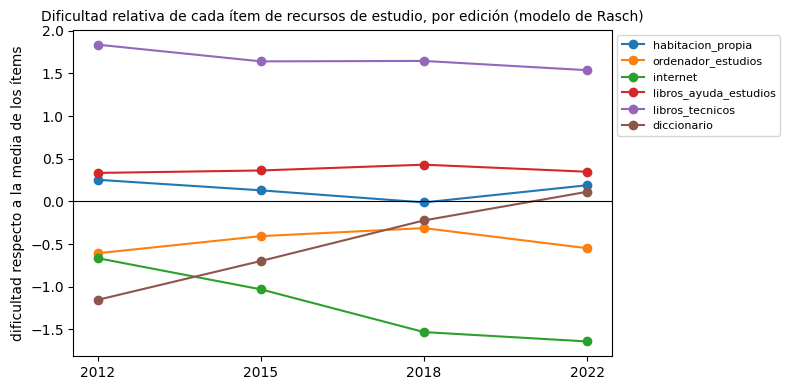

Parecido entre la suma y la puntuación IRT:


,alumnos con 4 o 5 respuestas (% de los que tienen subíndice),"r suma-IRT, todos","r suma-IRT, 6 respuestas","r suma-IRT, 4 o 5 respuestas",r suma-HEDRES,r IRT-HEDRES
2012,4.2,0.996,0.997,0.987,0.806,0.816
2015,5.8,0.996,0.997,0.988,0.787,0.795
2018,4.6,0.996,0.997,0.988,0.785,0.792
2022,22.4,0.990,0.998,0.981,NaN,NaN


asignatura ciencias                lectura                matemáticas               
edición        2012 2015 2018 2022    2012 2015 2018 2022        2012 2015 2018 2022
versión                                                                             
IRT             6.9  7.6  6.7  8.0     7.8  8.8  7.2  7.5         7.3  7.9  7.6  8.2
suma            6.8  7.6  6.8  8.7     7.8  8.9  7.5  8.3         7.2  7.8  7.6  8.8

In [13]:
ITEMS_ESTUDIO = SUBINDICES['recursos_estudio']

# 1. Dificultad de cada ítem (más negativa = más alumnos lo tienen)
dificultades = pd.DataFrame({'2012-2022': calibrar_rasch(alumnos, ITEMS_ESTUDIO),
                             **{edicion: calibrar_rasch(grupo, ITEMS_ESTUDIO) for edicion, grupo in alumnos.groupby('year')}})
print('Dificultad de cada ítem:')
display(dificultades.round(2))
relativas = (dificultades - dificultades.mean())[EDICIONES_RECURSOS]
print('Dificultad de cada ítem respecto a la media de los ítems de su edición:')
display(relativas.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
for item in ITEMS_ESTUDIO:
    ax.plot([str(edicion) for edicion in EDICIONES_RECURSOS], relativas.loc[item], marker='o', label=item)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('dificultad respecto a la media de los ítems')
ax.set_title('Dificultad relativa de cada ítem de recursos de estudio, por edición (modelo de Rasch)', fontsize=10)
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_alumno_irt_dificultades.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Puntuación IRT y su parecido con la suma
alumnos['recursos_estudio_irt'] = puntuacion_eap(alumnos, ITEMS_ESTUDIO, dificultades['2012-2022'], RESPUESTAS_MINIMAS['recursos_estudio'])
respondidos = alumnos[ITEMS_ESTUDIO].notna().sum(axis=1)
filas = {}
for edicion, grupo in alumnos.groupby('year'):
    seis = respondidos.loc[grupo.index] == len(ITEMS_ESTUDIO)
    filas[edicion] = {'alumnos con 4 o 5 respuestas (% de los que tienen subíndice)': round(100 * (~seis & grupo['recursos_estudio'].notna()).sum() / grupo['recursos_estudio'].notna().sum(), 1),
                      'r suma-IRT, todos': grupo['recursos_estudio'].corr(grupo['recursos_estudio_irt']),
                      'r suma-IRT, 6 respuestas': grupo.loc[seis, 'recursos_estudio'].corr(grupo.loc[seis, 'recursos_estudio_irt']),
                      'r suma-IRT, 4 o 5 respuestas': grupo.loc[~seis, 'recursos_estudio'].corr(grupo.loc[~seis, 'recursos_estudio_irt']),
                      'r suma-HEDRES': grupo['recursos_estudio'].corr(grupo['HEDRES']), 'r IRT-HEDRES': grupo['recursos_estudio_irt'].corr(grupo['HEDRES'])}
print('Parecido entre la suma y la puntuación IRT:')
display(pd.DataFrame(filas).T.round(3))

# 3. Puntos de nota por una desviación típica de cada versión, con los demás subíndices y el origen social
filas = []
for asignatura, dominio in ASIGNATURAS.items():
    for edicion, grupo in alumnos.groupby('year'):
        for version in ('recursos_estudio', 'recursos_estudio_irt'):
            ajuste = estimar_con_pv(grupo, dominio, lambda datos, columna: regresion_dentro_de_grupos(datos, columna, [version, 'riqueza_hogar', 'libros'] + CONTROLES_ORIGEN, ['CNT'], peso_col='SENWT'))
            filas.append({'asignatura': asignatura, 'edición': edicion, 'versión': 'suma' if version == 'recursos_estudio' else 'IRT',
                          'puntos por desviación típica': ajuste.loc[version, 'por desviación típica']})
pd.DataFrame(filas).pivot_table(index='versión', columns=['asignatura', 'edición'], values='puntos por desviación típica').round(1)

**Qué se ve.**

* **Ningún ítem cambia de golpe en 2022.** Respecto a los demás ítems de su edición, el diccionario se vuelve más difícil y el internet más fácil, pero de forma gradual desde 2012 (el diccionario pasa de −1,15 en 2012 a −0,70, −0,22 y 0,11; el internet, de −0,67 a −1,03, −1,53 y −1,64): reflejan que cada vez menos alumnos tienen diccionario en casa y más tienen internet, no un cambio de pregunta. Los ítems que cambiaron de redacción en 2022 se mueven poco: el ordenador (que pasa a incluir tablets) de −0,31 en 2018 a −0,55, y los libros de ayuda (que pasan a preguntarse en número) de 0,43 a 0,35.
* **La puntuación IRT y la suma ordenan a los alumnos casi igual**: correlación de 0,990 a 0,996 según la edición; de 0,997 a 0,998 entre los alumnos que respondieron los seis ítems y de 0,981 a 0,988 entre los que respondieron cuatro o cinco. En 2022 estos últimos son el 22,4 % de los alumnos con subíndice (entre el 4,2 % y el 5,8 % antes), y aun así el prorrateo de la suma apenas se separa de la puntuación IRT.
* **Las dos se parecen igual al índice oficial de recursos educativos** (`HEDRES`): la IRT algo más (de 0,792 a 0,816, frente a 0,785-0,806 de la suma).
* **La relación con la nota no cambia**: con los demás subíndices y el origen social, una desviación típica de la suma se asocia a entre 6,8 y 8,9 puntos y una de la puntuación IRT, a entre 6,7 y 8,8, en las tres asignaturas. La mayor diferencia está en 2022 (por ejemplo, 8,7 frente a 8,0 puntos en ciencias).

**Decisión**: el subíndice se mantiene como suma de ítems, más fácil de explicar; la puntuación IRT queda como comprobación de robustez del modelo.

### Diferencias entre países

La estimación anterior da a cada ítem la misma dificultad en todos los países. Pero un ítem puede ser más raro o más común en un país por motivos que no tienen que ver con los recursos (costumbres, tamaño de las viviendas, uso de diccionarios en papel): es el funcionamiento diferencial del ítem entre países, y por eso la OCDE permite que un ítem tenga una dificultad propia en un país cuando allí funciona distinto. Dos comprobaciones:

1. **Dificultad de cada ítem en cada país** (las cuatro ediciones juntas; muestras de 20.000 alumnos por país), respecto a la media de los ítems de ese país, comparada con la internacional. Una diferencia de más de 0,5 en la escala del modelo suele considerarse moderada, y de más de 1, grande.
2. **Puntuación IRT con las dificultades propias de cada país**, comparada con la suma y con la puntuación con dificultades internacionales: su parecido dentro de cada país-edición y su relación con la nota (la regresión de la sección 9, en las tres asignaturas).

Ítems sin ninguna respuesta en algún país: {'ISR': ['habitacion_propia']}


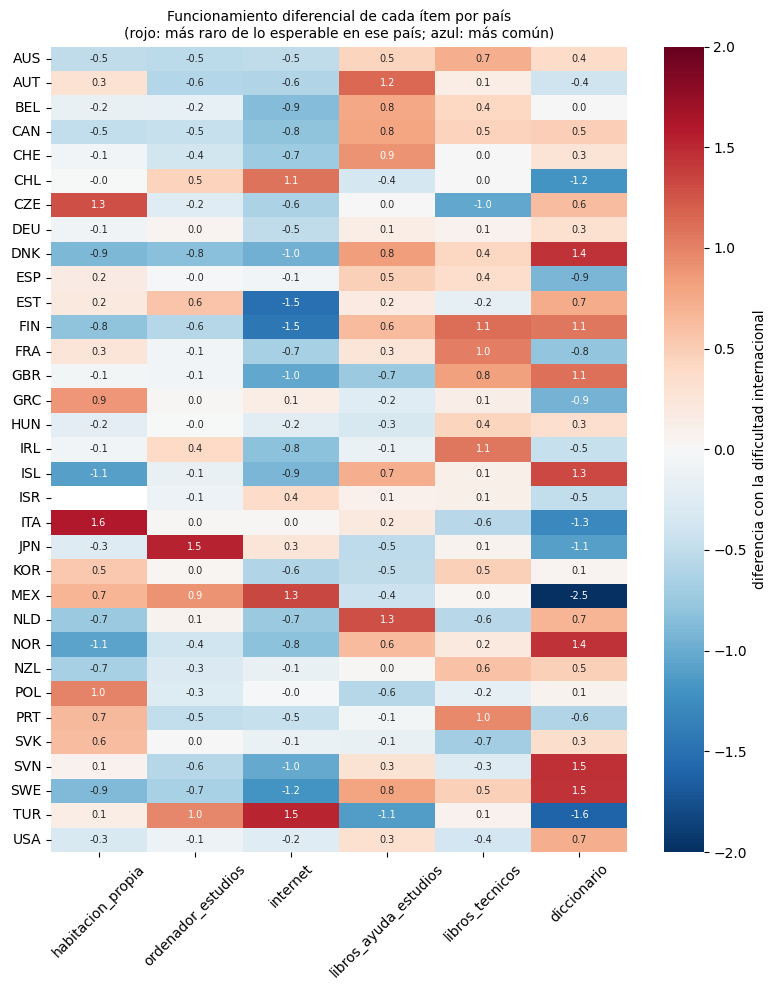

pares país-ítem con diferencia mayor que 0,5: 94 de 197; mayor que 1: 32


,"países con diferencia > 0,5",países con diferencia > 1,país más raro,diferencia máxima,país más común,diferencia mínima
habitacion_propia,16,4,ITA,1.61,ISL,-1.11
ordenador_estudios,10,1,JPN,1.55,DNK,-0.83
internet,22,8,TUR,1.52,EST,-1.50
libros_ayuda_estudios,15,3,NLD,1.29,TUR,-1.11
libros_tecnicos,11,4,FIN,1.12,CZE,-1.04
diccionario,20,12,SVN,1.47,MEX,-2.52


Correlación con la suma dentro de cada país-edición: {'IRT, dificultades internacionales': np.float64(0.995), 'IRT, dificultades de cada país': np.float64(0.992)}
Por país, correlación de la suma con la puntuación de dificultades propias: mínima 0.988 (IRL), mediana 0.996


Puntos de nota por desviación típica de cada versión (con los demás subíndices y el origen social):


asignatura                        ciencias                lectura                matemáticas               
edición                               2012 2015 2018 2022    2012 2015 2018 2022        2012 2015 2018 2022
versión                                                                                                    
IRT, dificultades de cada país         7.0  7.8  6.8  8.1     7.9  8.9  7.4  7.6         7.4  8.0  7.7  8.3
IRT, dificultades internacionales      6.9  7.6  6.7  8.0     7.8  8.8  7.2  7.5         7.3  7.9  7.6  8.2
suma                                   6.8  7.6  6.8  8.7     7.8  8.9  7.5  8.3         7.2  7.8  7.6  8.8

In [14]:
# 1. Diferencia de cada país con la dificultad relativa internacional (> 0: el ítem lo tienen menos alumnos de lo que tocaría por su nivel)
# (cada país se compara con los ítems que tiene: Israel no pregunta por la habitación propia)
dificultades_pais = {pais: calibrar_rasch(grupo, ITEMS_ESTUDIO, alumnos=20000) for pais, grupo in alumnos.groupby('CNT')}
internacional = dificultades['2012-2022']
diferencia_pais = pd.DataFrame({pais: (dificultad - dificultad.mean()) - (internacional - internacional[dificultad.notna()].mean())
                                for pais, dificultad in dificultades_pais.items()}).T
print('Ítems sin ninguna respuesta en algún país:', {pais: list(dificultad[dificultad.isna()].index) for pais, dificultad in dificultades_pais.items() if dificultad.isna().any()})
fig, ax = plt.subplots(figsize=(8, 10))
sns.heatmap(diferencia_pais, annot=True, fmt='.1f', cmap='RdBu_r', vmin=-2, vmax=2, center=0, cbar_kws={'label': 'diferencia con la dificultad internacional'}, ax=ax, annot_kws={'fontsize': 7})
ax.set_title('Funcionamiento diferencial de cada ítem por país\n(rojo: más raro de lo esperable en ese país; azul: más común)', fontsize=10)
ax.tick_params(axis='x', labelrotation=45)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_recursos_alumno_irt_paises.png', dpi=300, bbox_inches='tight')
plt.show()
diferencia_absoluta = diferencia_pais.abs()
print(f'pares país-ítem con diferencia mayor que 0,5: {int((diferencia_absoluta > 0.5).sum().sum())} de {int(diferencia_pais.notna().sum().sum())}; mayor que 1: {int((diferencia_absoluta > 1).sum().sum())}')
display(pd.DataFrame({'países con diferencia > 0,5': (diferencia_absoluta > 0.5).sum(), 'países con diferencia > 1': (diferencia_absoluta > 1).sum(),
                      'país más raro': diferencia_pais.idxmax(), 'diferencia máxima': diferencia_pais.max().round(2),
                      'país más común': diferencia_pais.idxmin(), 'diferencia mínima': diferencia_pais.min().round(2)}))

# 2. Puntuación con las dificultades propias de cada país, frente a la suma y a la puntuación con dificultades internacionales
alumnos['recursos_estudio_irt_pais'] = pd.concat([puntuacion_eap(grupo, ITEMS_ESTUDIO, dificultades_pais[pais], RESPUESTAS_MINIMAS['recursos_estudio'])
                                                  for pais, grupo in alumnos.groupby('CNT')])
VERSIONES = {'suma': 'recursos_estudio', 'IRT, dificultades internacionales': 'recursos_estudio_irt', 'IRT, dificultades de cada país': 'recursos_estudio_irt_pais'}
centradas = centrar_en_grupos(alumnos, list(VERSIONES.values()), ['CNT', 'year'], peso_col='SENWT')
print('Correlación con la suma dentro de cada país-edición:', {version: round(centradas['recursos_estudio'].corr(centradas[columna]), 3) for version, columna in VERSIONES.items() if columna != 'recursos_estudio'})
correlacion_pais = centradas.join(alumnos['CNT']).groupby('CNT').apply(lambda grupo: grupo['recursos_estudio'].corr(grupo['recursos_estudio_irt_pais']))
print(f"Por país, correlación de la suma con la puntuación de dificultades propias: mínima {correlacion_pais.min():.3f} ({correlacion_pais.idxmin()}), mediana {correlacion_pais.median():.3f}")

filas = []
for asignatura, dominio in ASIGNATURAS.items():
    for edicion, grupo in alumnos.groupby('year'):
        for version, variable in VERSIONES.items():
            ajuste = estimar_con_pv(grupo, dominio, lambda datos, columna: regresion_dentro_de_grupos(datos, columna, [variable, 'riqueza_hogar', 'libros'] + CONTROLES_ORIGEN, ['CNT'], peso_col='SENWT'))
            filas.append({'asignatura': asignatura, 'edición': edicion, 'versión': version, 'puntos por desviación típica': ajuste.loc[variable, 'por desviación típica']})
print('Puntos de nota por desviación típica de cada versión (con los demás subíndices y el origen social):')
pd.DataFrame(filas).pivot_table(index='versión', columns=['asignatura', 'edición'], values='puntos por desviación típica').round(1)

**Qué se ve.**

* **Muchos ítems funcionan distinto según el país**: 94 de los 197 pares país-ítem superan una diferencia de 0,5 y 32 superan 1 (Israel no pregunta por la habitación propia). Los patrones son reconocibles:
  * el diccionario es mucho más común de lo esperable en México (−2,52) y mucho más raro en los países nórdicos y Eslovenia (hasta +1,47): es el ítem con más países por encima de 1 (12);
  * el internet es más raro de lo esperable en Turquía (+1,52) y más común en Estonia (−1,50);
  * la habitación propia es más rara en Italia (+1,61) y más común en Islandia (−1,11), seguramente por costumbres y tamaño de las viviendas;
  * el ordenador es más raro en Japón (+1,55).
* **Dentro de cada país no cambia nada**: la puntuación con las dificultades propias de cada país tiene una correlación de 0,992 con la suma dentro de cada país-edición (por país, entre 0,988 en Irlanda y una mediana de 0,996), y su relación con la nota es prácticamente la misma (entre 6,8 y 8,9 puntos por desviación típica, igual que la suma, en las tres asignaturas). Dentro de un país cada ítem funciona igual para todos sus alumnos, así que la suma los sigue ordenando bien.

**Consecuencia**: el modelo, que compara alumnos dentro de cada país-edición o de cada centro, no se ve afectado. Lo que sí depende de estos ítems es la comparación del nivel de recursos de estudio entre países (sección 7): hay que leerla con cautela.

## 13. Guardado

Una fila por alumno de las cuatro ediciones con sus claves, pesos, ítems armonizados y subíndices, en `data/intermediate/recursos_alumno_anual/pisa_recursos_alumno_anual.parquet`, para los siguientes análisis y para el modelo.

In [15]:
COLUMNAS_GUARDADAS = CLAVES_ALUMNO + ['year'] + PESOS_ALUMNO + list(ITEMS_HOGAR) + list(SUBINDICES)
ruta_recursos = os.path.join(RUTA_INTERMEDIOS, 'recursos_alumno_anual')
os.makedirs(ruta_recursos, exist_ok=True)
ruta_tabla = os.path.join(ruta_recursos, 'pisa_recursos_alumno_anual.parquet')
alumnos[COLUMNAS_GUARDADAS].astype({columna: 'float32' for columna in list(ITEMS_HOGAR) + list(SUBINDICES)}).to_parquet(ruta_tabla, index=False)
print(f'{len(alumnos)} alumnos guardados en {ruta_tabla} ({os.path.getsize(ruta_tabla) / 1e6:.0f} MB)')

1066807 alumnos guardados en ../../data/intermediate\recursos_alumno_anual\pisa_recursos_alumno_anual.parquet (14 MB)


**Qué se ve.** 1.066.807 alumnos de las cuatro ediciones guardados en 14 MB.

## Hallazgos y próximos pasos

* **`HOMEPOS` mezcla recursos de estudio y riqueza**, y es un componente del `ESCS`. En 2022 no hay subíndices oficiales que los separen: por eso se construyen subíndices propios por suma de ítems.
* **Tres subíndices comparables de 2012 a 2022**, cada uno parecido a su índice oficial y poco a los demás:
  * **recursos de estudio** (habitación propia, ordenador, internet, libros de ayuda, libros técnicos y diccionario), parecido al índice oficial de recursos educativos del hogar (correlación de 0,79 a 0,81). Es la variable de recursos del alumno en el modelo;
  * **riqueza del hogar** (coches y baños), parecido al índice oficial de riqueza (0,72 a 0,80). Es origen social: con el origen social en el modelo, su relación con la nota desaparece;
  * **libros en casa**, parecido a las posesiones culturales (0,48 a 0,50). Se trata como capital cultural de la familia (origen social), un control.
* **Huecos que no son al azar**: los alumnos sin subíndice sacan entre 19 y 94 puntos menos que la media de su país, según el subíndice, la asignatura y la edición. En 2022 los recursos de estudio faltan para el 15,4 % de los alumnos (hasta el 34 % en Noruega), por las preguntas de tipos de libros; Israel no tiene riqueza en ninguna edición.
* **La variación está entre alumnos, no en el tiempo**: entre el 67,5 % y el 75,5 % de la varianza de los subíndices está entre alumnos del mismo centro, y solo entre el 0,5 % y el 1,1 % entre ediciones de un mismo país. Los subíndices apenas cambian dentro de cada país entre 2012 y 2022.
* **Relación con la nota**: con el origen social y los demás subíndices en el modelo, una desviación típica más de recursos de estudio se asocia a entre 6,8 y 8,9 puntos más dentro de cada país, de forma estable entre ediciones y entre matemáticas, lectura y ciencias.
* **Sumar ítems basta**: una puntuación IRT (modelo de Rasch) ordena a los alumnos casi igual que la suma (correlación de 0,990 a 0,996), ningún ítem cambia de golpe en 2022 y la relación con la nota es la misma. Muchos ítems funcionan distinto según el país (94 de 197 pares país-ítem con diferencia moderada), pero dentro de cada país la suma sigue ordenando igual a los alumnos (correlación de 0,992 con una puntuación con dificultades propias de cada país): no afecta al modelo, sí a la comparación del nivel entre países. La suma se mantiene; la IRT queda como comprobación.
* **Los recursos del centro vistos por el alumno no sirven**: cambian de asignatura o de escala entre ediciones, son sobre todo percepciones individuales y no se relacionan con la nota.

* **Efecto techo**: entre el 45,3 % y el 53,6 % de los alumnos tiene los seis recursos de estudio, así que el subíndice distingue sobre todo a los que les falta alguno.

Comprobaciones previstas en el modelado:

* **Efecto techo**: probar los recursos de estudio por tramos (faltan dos o más, falta uno, los tiene todos) y medir el % de alumnos con los seis en cada perfil y edición.
* **IRT**: repetir las estimaciones con la puntuación IRT (dificultades internacionales y propias de cada país) y con una versión IRT ampliada que use ítems que no están en todas las ediciones (escritorio y sitio tranquilo hasta 2018, software educativo como dos ítems según la edición, tipos de libros de 2022 con su escala de número), anclada en los ítems estables entre ediciones (habitación propia, libros de ayuda, libros técnicos). Si los efectos salen mayores, el ruido de la suma los estaría atenuando.